# Trump on Truth Social as a complex system
### Bursty self-excitation, a hub-and-spoke attention network, and heavy-tailed cascades of public attention

**Data.** 37,412 posts from 28 Apr 2022 to 29 Oct 2026, together with prices, Wikipedia pageviews in 24 languages, and brand stock prices. The interpretations below quote the numbers from this run (data up to 29 Oct 2026). All seeds are fixed, so re-running on the same cached data reproduces them.

**Why a complex system?** One person posting looks simple. But the *activity* emerges from feedback between his own posts, the news, his audience, and the actors he names. Its *effects* spread through social systems (audiences, markets, editors, foreign publics) that respond collectively and non-linearly. We study three layers:
1. **The process:** when he posts (point processes, burstiness, self-excitation, long memory).
2. **The structure:** what he talks about and how it is organised (networks, communities, multiplex layers, regime shifts).
3. **The impact:** how other systems respond (event studies against null models, cascade-size distributions, endogenous vs exogenous bursts, and a mechanistic opinion-dynamics model).

**Key findings at a glance**
| | Finding | Complex-systems reading |
|---|---|---|
| A | Inter-event times are bursty (B = 0.45, still 0.41 after removing the day/night cycle) and have long memory (DFA α = 0.62 hourly, 0.77 daily). A two-timescale Hawkes model puts the branching ratio at n ≈ 0.66: about 2/3 of posts are triggered by earlier posts, via ~1-minute sprees and ~15-minute follow-ups. | A **self-exciting, sub-critical** process; it never approaches n = 1 |
| B | Engagement is heavy-tailed. ALL-CAPS, exclamations, emotional intensity, tariffs and war raise likes; endorsements cut them by 38%. Reposting follows **linear preferential attachment** (γ = 1.02) and is very unequal (Gini 0.73). | Rich-get-richer **amplification** |
| C | The attention network is **disassortative** (r = −0.28) with 7 robust communities (z = 19 vs null): foreign affairs, parties and Congress, legal cases, media and platforms, alt-media, Hungary, the Fed. Only 30% of ties survive from one quarter to the next. | A **hub-and-spoke**, rapidly rewiring network |
| D | Markets: **tariff posts raise S&P 500 volatility ×1.5 for 1–3 hours**, with an unpredictable direction. Other posts have no effect, and there is no effect at the daily scale. | A fast shock, absorbed within the day |
| E | Stance towards countries **shifts at the inauguration**: from −0.14 to +0.11 (p ≈ 10⁻³⁰). War, trade and diplomacy are fused: layer overlap is 0.78 and 88% of countries are multi-issue. | A **regime shift** under a change of role, and a **multiplex** without compartments |
| F | Posts move attention far beyond politics: **26 of 40 Wikipedia targets** respond (13% of events at z > 2 vs 2.3% expected), and entertainment responds most. Attention cascades are **heavy-tailed** (the top 10% of events carry 84% of the extra views). Posts about a country raise attention to Trump *in that country's language* (z = 7.2). Brands he names see extreme stock moves (6 of 37 events in the most extreme 2%, p = 9×10⁻⁵). | **Heavy-tailed cascades** of collective attention |
| G | In a bounded-confidence model driven by his real posts, a one-sided broadcaster **homogenises** opinion (the SD halves) and pulls it towards his stance. Below a confidence threshold (ε ≈ 0.3) the population stays fragmented. | A **phase transition** between fragmentation and consensus |

**What was tested and dropped.** These analyses were run and gave null or uninformative results, so they are not shown:
* structural balance of a signed actor network: weak and dependent on the definition;
* policy-uncertainty, approval and prediction-market responses: no significant information flow after FDR;
* daily S&P/sector/country-ETF event studies, transfer entropy and Granger tests: no significant flow;
* random-matrix and MST changes in market structure;
* GDELT bilateral US–country relations: no response to posts.

The code for these remains in `tscs/`.

| Complexity concept | Section | Key reference |
|---|---|---|
| Burstiness, memory, bursty trains | A2–A3 | Goh & Barabási 2008; Karsai et al. 2012 |
| Heavy tails (CSN fitting, likelihood-ratio tests) | A2, B1, B3, F5 | Clauset, Shalizi & Newman 2009 |
| Long-range correlations (DFA) | A4 | Peng et al. 1994 |
| Self-excited Hawkes processes, branching ratio, criticality | A5 | Hawkes 1971; Filimonov & Sornette 2012; Bacry et al. 2015 |
| Linguistic laws (Zipf, Heaps) | B2 | Zipf 1949; Heaps 1978 |
| Preferential-attachment kernel | B3 | Jeong, Néda & Barabási 2003 |
| Co-occurrence networks, small world, assortativity, rich club | C1–C2 | Watts & Strogatz 1998; Newman 2002; Colizza et al. 2006 |
| Disparity-filter backbone | C3 | Serrano, Boguñá & Vespignani 2009 |
| Community detection vs null models | C4 | Blondel et al. 2008; Guimerà et al. 2004 |
| Temporal networks | C5 | Holme & Saramäki 2012 |
| Event studies with placebo nulls and FDR | D, F | MacKinlay 1997; Benjamini & Hochberg 1995 |
| Regime shifts (change points with permutation tests) | E1 | Killick & Eckley 2014 |
| Multiplex networks, participation coefficient | E2 | Battiston, Nicosia & Latora 2014 |
| Cascade-size distributions | F5 | Crane & Sornette 2008; Goel et al. 2016 |
| Endogenous vs exogenous bursts | F6 | Crane & Sornette 2008 |
| Bounded-confidence opinion dynamics with mass media | G | Deffuant et al. 2000; González-Avella et al. 2005 |

## 0. Configuration
Set `DEMO = True` to run on **synthetic data**, with no internet needed. That mode is only for checking that the code runs; its results are meaningless. The generator plants known effects, so DEMO mode also checks that each estimator recovers them.

With `DEMO = False`, the first run downloads everything into `data/`. Later runs read from that cache. Set `REFRESH = True` to re-download.

In [1]:
DEMO = False          # True -> synthetic test data (offline). False -> real data.
REFRESH = False       # re-download the cached data
FAST = False          # fewer bootstrap / null-model samples (quicker iteration)

DATA_DIR = "data_demo" if DEMO else "data"
FIG_DIR = "figs_demo" if DEMO else "figs"
START, END = "2022-04-28", None        # one test post on 2022-02-14, then nothing until 2022-04-28 (a 73-day gap)

N_BOOT = 30 if FAST else 200           # power-law GOF bootstrap
N_NULL_NET = 5 if FAST else 30         # network null models
N_PLACEBO = 500 if FAST else 3000      # event-study placebos

# --- external data options -------------------------------------------------------------
CONTACT_EMAIL = None     # e.g. "you@university.edu": Wikimedia then allows ~200 req/min instead of ~10
USE_WIKI = True          # Wikipedia pageviews (Part F)

KEY_DATES = {"2022-11-15": "campaign launch", "2024-11-05": "election", "2025-01-20": "inauguration",
             "2025-04-02": "'Liberation Day' tariffs"}

In [2]:
import sys, warnings
sys.path.insert(0, ".")
import numpy as np, pandas as pd, networkx as nx, matplotlib.pyplot as plt
from scipy import stats
from tscs import data as D, text as TX, pointproc as PP, networks as NW, markets as MK, plotting as PL
from tscs import geo as GEO, external as EXT, culture as CU
PL.setup(); warnings.filterwarnings("ignore", category=RuntimeWarning); warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 170, "display.max_columns", 30, "display.precision", 4)
C = PL.C
save = lambda fig, name: PL.save(fig, name, FIG_DIR)
SUMMARY = {}  # key results collected for the final table

if DEMO:
    from tscs import synthetic
    info = synthetic.generate(DATA_DIR)
    print("DEMO MODE - synthetic data. Planted parameters:", info["true"])
print("VADER sentiment available:", TX._VADER is not None, "(falls back to a domain lexicon)")

VADER sentiment available: True (falls back to a domain lexicon)


## 1. Data
All loading happens here, once. Every source is cached in `data/`, so reruns are fast and work offline.

| Dataset | Source | Used in |
|---|---|---|
| Truth Social posts (37k, Feb 2022 – Oct 2026) | CNN archive (ix.cnn.io), about 21 MB | everywhere |
| Prices: daily since 2022, hourly for the last ~2–3 years | Yahoo Finance (`yfinance`) | D |
| Wikipedia pageviews (English issue and culture articles; the *Donald Trump* article in 24 languages) | Wikimedia REST API | F |

**Cleaning decisions**, all checked on the real archive:
* The archive is **plain text**, not HTML.
* About 20% of posts are **ReTruths**. In the archive they look like `RT @handleTEXT…`, with the handle glued to the text. We recover the handle by longest match against a dictionary of handles seen in unambiguous places; about 40% of ReTruths are self-reposts. Some posts have garbled characters from a text-encoding error upstream (`Worldâ€™s`); these are repaired.
* About 41% of posts are **media or link only**, with no text of his own.
* About 8% of original posts are **quotations** of headlines or TV hosts (`“…”`). They are kept for attention and timing analyses, but excluded when we measure *his* sentiment (`own`).
* Tagging takes about 1 minute, so its result is cached.

In [3]:
import os
arch = D.download_posts(DATA_DIR, refresh=REFRESH)
tag_cache = os.path.join(DATA_DIR, f"posts_tagged_v{TX.TAG_VERSION}.pkl")
if os.path.exists(tag_cache) and os.path.getmtime(tag_cache) > os.path.getmtime(arch) and not REFRESH:
    posts = pd.read_pickle(tag_cache)
else:
    posts = TX.tag_posts(D.load_posts(DATA_DIR))
    posts.to_pickle(tag_cache)
posts = posts[posts.t_utc >= pd.Timestamp(START, tz="UTC")].copy()
if END: posts = posts[posts.t_utc <= pd.Timestamp(END, tz="UTC")].copy()
orig = posts[~posts.is_repost & ~posts.media_only].copy()   # posts with his own text
own = orig[~orig.is_quote].copy()                           # ... excluding quotations of others (for sentiment/stance)
quality = pd.Series({
    "posts": len(posts), "from": f"{posts.t_et.min():%Y-%m-%d}", "to": f"{posts.t_et.max():%Y-%m-%d}",
    "ReTruths (reposts)": f"{posts.is_repost.mean():.1%}", "  of which self-reposts": f"{posts[posts.is_repost].is_self_repost.mean():.1%}",
    "media/link only": f"{posts.media_only.mean():.1%}", "quotation posts": f"{orig.is_quote.mean():.1%} of original",
    "original-text posts (orig)": len(orig), "own-voice posts (own)": len(own),
    "missing engagement counts": int(posts.favourites_count.isna().sum()),
    "duplicate texts among orig": int(orig.text_nourl.duplicated().sum())})
display(quality.to_frame("value"))
topic_share = orig[[c for c in orig if c.startswith('topic_')]].mean().sort_values(ascending=False)
print("Share of original posts touching each topic:\n", topic_share.round(3).to_string())

,value
posts,37412
from,2022-04-28
to,2026-10-29
ReTruths (reposts),20.1%
of which self-reposts,39.2%
media/link only,41.3%
quotation posts,8.7% of original
original-text posts (orig),16480
own-voice posts (own),15042
missing engagement counts,9


Share of original posts touching each topic:
 topic_elections          0.293
topic_markets_economy    0.165
topic_legal              0.143
topic_immigration        0.128
topic_endorsement        0.109
topic_foreign_war        0.080
topic_energy             0.080
topic_media_attack       0.035
topic_tariffs_trade      0.025
topic_fed_rates          0.007
topic_crypto             0.002


In [4]:
px = D.download_prices(D.all_daily_tickers(), DATA_DIR, start="2022-01-01", interval="1d", refresh=REFRESH)
tdays = px["SPY"].dropna().index
px = px.loc[tdays]                               # trading days only (BTC weekend moves roll into Monday)
rets = MK.log_returns(px)
pxh = D.download_prices(["SPY", "QQQ", "^VIX", "BTC-USD", "DJT"], DATA_DIR, interval="60m", refresh=REFRESH)

In [5]:
EXT.CONTACT = CONTACT_EMAIL
# Wikipedia: ~65 requests on the first run (about 10/min without CONTACT_EMAIL), then cached
fa = EXT.foreign_trump_attention(data_dir=DATA_DIR, start=START) if USE_WIKI else pd.DataFrame()   # 24 languages
ia = EXT.issue_attention(data_dir=DATA_DIR, start=START) if USE_WIKI else pd.DataFrame()           # policy/geo issues
cv = pd.DataFrame({a: EXT.wiki_pageviews(a, start=START, data_dir=DATA_DIR) for a in CU.CULTURE}) if USE_WIKI else pd.DataFrame()
bpx = D.download_prices(sorted(set(CU.BRAND_TICKERS.values()) | {"SPY"}), DATA_DIR, start="2022-01-01", interval="1d",
                        fname="prices_brands_1d.csv", refresh=REFRESH)
brets = MK.log_returns(bpx.loc[bpx["SPY"].dropna().index])

def _rng(ix):
    return (f"{pd.Timestamp(ix.min()):%Y-%m-%d}", f"{pd.Timestamp(ix.max()):%Y-%m-%d}") if len(ix) else ("-", "-")
inv = [("Truth Social posts", len(posts), *_rng(posts.t_et.dt.tz_localize(None))),
       ("daily prices (tickers x days)", f"{px.shape[1]} x {px.shape[0]}", *_rng(px.index)),
       ("hourly prices", f"{pxh.shape[1]} x {pxh.shape[0]}", *_rng(pxh.index.tz_localize(None))),
       ("brand stock prices", ", ".join(c for c in bpx.columns if c != "SPY"), *_rng(bpx.index)),
       ("Wikipedia: Trump article, languages", fa.shape[1], *_rng(fa.index)),
       ("Wikipedia: policy/geo issue articles", ia.shape[1], *_rng(ia.index)),
       ("Wikipedia: culture/brand/sport/health/place articles", cv.shape[1], *_rng(cv.index))]
display(pd.DataFrame(inv, columns=["dataset", "size", "from", "to"]).set_index("dataset"))

,size,from,to
dataset,,,
Truth Social posts,37412,2022-04-28,2026-10-29
daily prices (tickers x days),67 x 1211,2022-01-03,2026-10-29
hourly prices,5 x 25394,2023-12-04,2026-10-30
brand stock prices,"AAPL, AEO, CBRL, INTC, KO, TSLA",2022-01-03,2026-10-29
"Wikipedia: Trump article, languages",24,2022-02-14,2026-10-28
Wikipedia: policy/geo issue articles,16,2022-02-14,2026-10-28
Wikipedia: culture/brand/sport/health/place articles,24,2022-02-14,2026-10-28


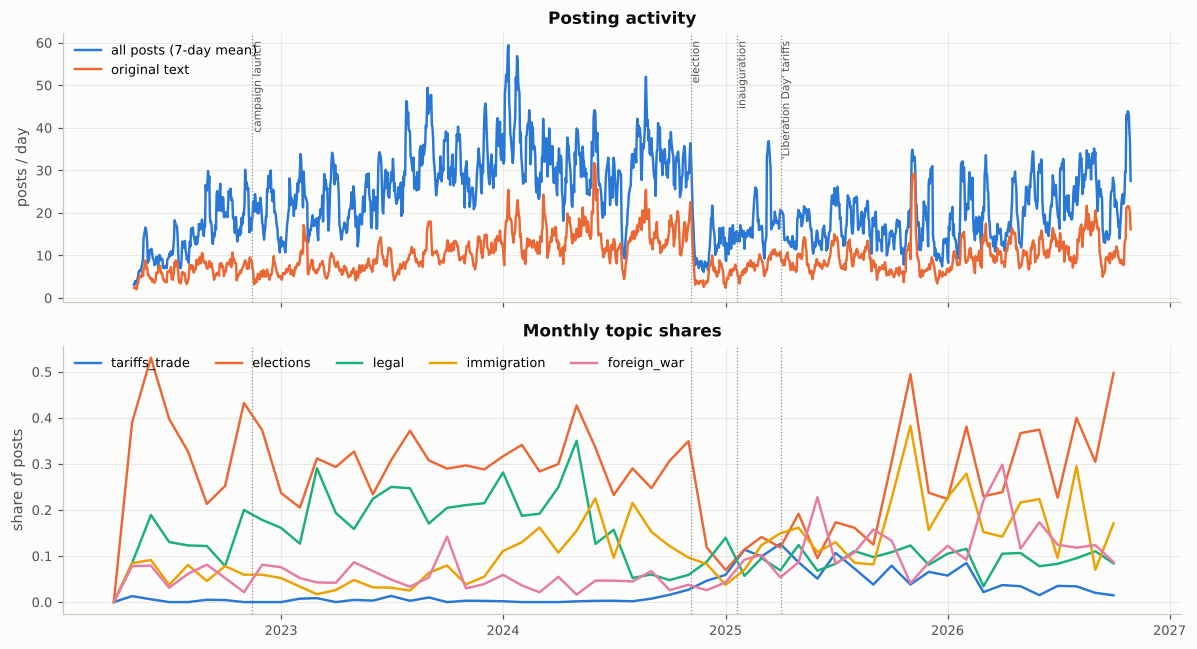

In [6]:
daily_all = posts.set_index("t_et").resample("D").size()
daily_orig = orig.set_index("t_et").resample("D").size()
monthly_topics = orig.set_index("t_et")[[f"topic_{k}" for k in ["tariffs_trade", "elections", "legal", "immigration", "foreign_war"]]].resample("MS").mean()

fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].plot(daily_all.index, daily_all.rolling(7).mean(), color=C[0], label="all posts (7-day mean)")
ax[0].plot(daily_orig.index, daily_orig.rolling(7).mean(), color=C[1], label="original text")
ax[0].set_ylabel("posts / day"); ax[0].legend(loc="upper left"); ax[0].set_title("Posting activity")
for i, c in enumerate(monthly_topics):
    ax[1].plot(monthly_topics.index, monthly_topics[c], color=C[i], label=c.replace("topic_", ""))
ax[1].set_ylabel("share of posts"); ax[1].legend(ncol=5, loc="upper left"); ax[1].set_title("Monthly topic shares")
for a in ax:
    for d, lab in KEY_DATES.items():
        a.axvline(pd.Timestamp(d, tz=D.ET), color=PL.GREY, lw=0.8, ls=":")
for d, lab in KEY_DATES.items():
    ax[0].text(pd.Timestamp(d, tz=D.ET), ax[0].get_ylim()[1] * 0.97, lab, fontsize=7, rotation=90, va="top", color=PL.INK2)
save(fig, "01_activity_topics");

## Part A. Temporal complexity of the posting process
Human activity is famously non-Poissonian: there are long silences and intense bursts (Barabási 2005). A Poisson process would give exponential inter-event times, burstiness $B=0$ and memory $M=0$. We measure these, then ask whether bursts come only from the day/night cycle or from **self-excitation**.

### A1. Circadian and weekly rhythm

Posts between midnight and 6am ET: 7.6%


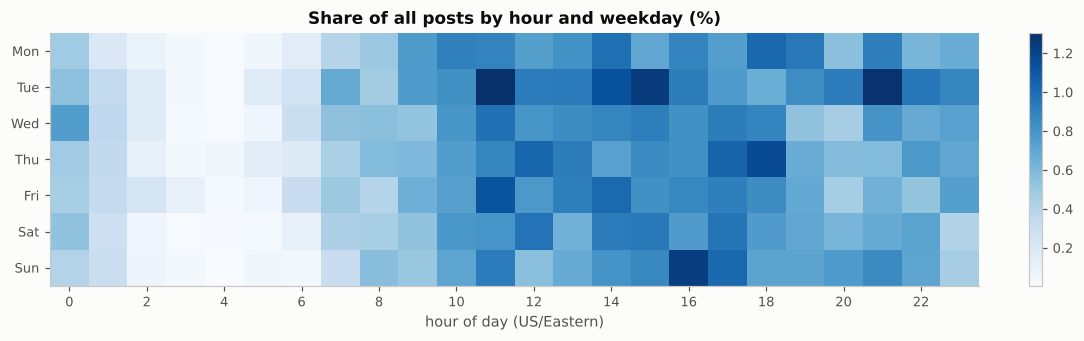

In [7]:
heat = posts.groupby(["weekday", "hour_et"]).size().unstack(fill_value=0)
heat = heat / heat.values.sum() * 100
fig, ax = plt.subplots(figsize=(10, 3.2))
im = ax.imshow(heat.values, aspect="auto", cmap="Blues")
ax.set_yticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]); ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("hour of day (US/Eastern)"); ax.set_title("Share of all posts by hour and weekday (%)"); ax.grid(False)
plt.colorbar(im, ax=ax, fraction=0.025)
save(fig, "A1_circadian");
night = posts.hour_et.isin([0, 1, 2, 3, 4, 5]).mean()
print(f"Posts between midnight and 6am ET: {night:.1%}")
SUMMARY["share_posts_midnight_6am"] = night

### A2. Inter-event times: burstiness, memory and heavy tails
* $B = (\sigma_\tau-\mu_\tau)/(\sigma_\tau+\mu_\tau)$; we also report the finite-size-corrected $B_n$ (Kim & Jo 2016).
* $M = \mathrm{corr}(\tau_i, \tau_{i+1})$. We compute it on $\log\tau$ too, which is robust to the heavy tail.
* We **rescale time by the empirical weekly activity profile**. Burstiness that survives this cannot be explained by the circadian rhythm alone (Jo et al. 2012).
* We fit the tail with the Clauset–Shalizi–Newman method: $x_{\min}$ by KS minimisation, MLE $\alpha$, a bootstrap GOF $p$, and Vuong likelihood-ratio tests against lognormal and exponential. A positive LR favours the power law.

In [8]:
tau = PP.interevent_times(posts.t_utc, "m"); tau = tau[tau > 0]
t_resc = PP.circadian_rescale(posts.t_et); tau_r = np.diff(t_resc) * 60; tau_r = tau_r[tau_r > 0]
rng = np.random.default_rng(0)
tau_pois = rng.exponential(tau.mean(), len(tau))
rows = []
for name, x in [("raw", tau), ("circadian-rescaled", tau_r), ("Poisson reference", tau_pois)]:
    rows.append(dict(series=name, mean_min=x.mean(), median_min=np.median(x), B=PP.burstiness(x),
                     B_n=PP.burstiness_finite(x), M=PP.memory_coefficient(x), M_log=PP.memory_coefficient(np.log(x))))
burst_tab = pd.DataFrame(rows).set_index("series"); display(burst_tab)

pl_tau = PP.fit_powerlaw(tau); PP.compare_tails(tau, pl_tau); PP.powerlaw_pvalue(tau, pl_tau, n_boot=N_BOOT)
pl_tau_r = PP.fit_powerlaw(tau_r); PP.compare_tails(tau_r, pl_tau_r)
display(pd.DataFrame({"raw": pl_tau.summary(), "rescaled": pl_tau_r.summary()}).T)
SUMMARY.update(B_raw=burst_tab.loc["raw", "B"], B_rescaled=burst_tab.loc["circadian-rescaled", "B"],
               M_log=burst_tab.loc["raw", "M_log"], tau_alpha=pl_tau.alpha, tau_xmin_min=pl_tau.xmin)

,mean_min,median_min,B,B_n,M,M_log
series,,,,,,
raw,63.3258,2.8427,0.4452,0.4486,0.0944,0.4097
circadian-rescaled,63.3281,3.4009,0.4080,0.4110,0.1255,0.4114
Poisson reference,63.2299,43.5510,0.0006,0.0006,-0.0019,0.0042


,alpha,alpha_se,xmin,n_tail,KS,p_gof,LR_vs_lognormal,p_LR_lognormal,LR_vs_exponential,p_LR_exponential
raw,4.3555,0.1226,657.8069,749.0,0.0605,0.005,-2.6316,8.4982e-03,-1.4844,0.1377
rescaled,3.4942,0.0674,414.2071,1370.0,0.0472,NaN,-4.0837,4.4326e-05,-0.8588,0.3905


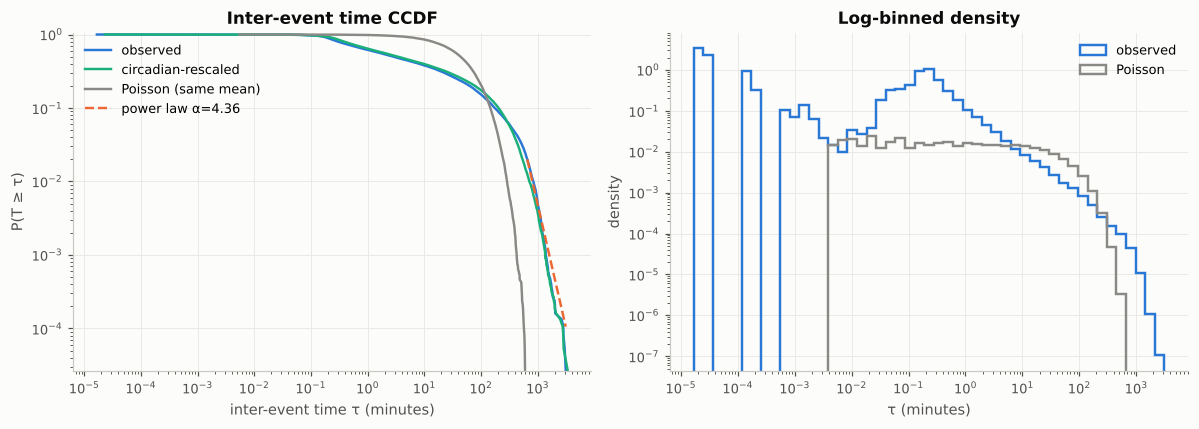

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for x, lab, col in [(tau, "observed", C[0]), (tau_r, "circadian-rescaled", C[2]), (tau_pois, "Poisson (same mean)", PL.GREY)]:
    xs, ys = PP.ccdf(x); ax[0].loglog(xs, ys, color=col, label=lab)
xx = np.logspace(np.log10(pl_tau.xmin), np.log10(tau.max()), 50)
ptail = np.mean(tau >= pl_tau.xmin)
ax[0].loglog(xx, ptail * (xx / pl_tau.xmin) ** (1 - pl_tau.alpha), "--", color=C[1], label=f"power law α={pl_tau.alpha:.2f}")
ax[0].set_xlabel("inter-event time τ (minutes)"); ax[0].set_ylabel("P(T ≥ τ)"); ax[0].legend(); ax[0].set_title("Inter-event time CCDF")
ax[0].set_ylim(1 / len(tau), 1.05)
bins = np.logspace(np.log10(tau.min()), np.log10(tau.max()), 50)
ax[1].hist(tau, bins=bins, density=True, histtype="step", color=C[0], lw=1.6, label="observed")
ax[1].hist(tau_pois, bins=bins, density=True, histtype="step", color=PL.GREY, lw=1.6, label="Poisson")
ax[1].set_xscale("log"); ax[1].set_yscale("log"); ax[1].set_xlabel("τ (minutes)"); ax[1].set_ylabel("density")
ax[1].legend(); ax[1].set_title("Log-binned density")
save(fig, "A2_interevent");

### A3. Bursty trains (Karsai et al. 2012)
Events closer than $\Delta t$ form a *bursty train*. If inter-event times are **independent**, the train size $E$ is geometric (exponential tail), even when $P(\tau)$ is heavy-tailed. A power-law $P(E)$ that beats the **shuffled-$\tau$ null** reveals *correlated* bursts, which is a signature of memory and self-excitation.

,window_min,mean_E,max_E,max_E_shuffled,beta_E,xmin,LR_vs_exp,p
0,10,2.6343,65,27,2.1288,2.0,-3.5588,0.0004
1,30,3.6790,111,29,3.7084,21.0,-2.5370,0.0112
2,120,7.4422,114,57,3.5844,26.0,-2.3792,0.0173


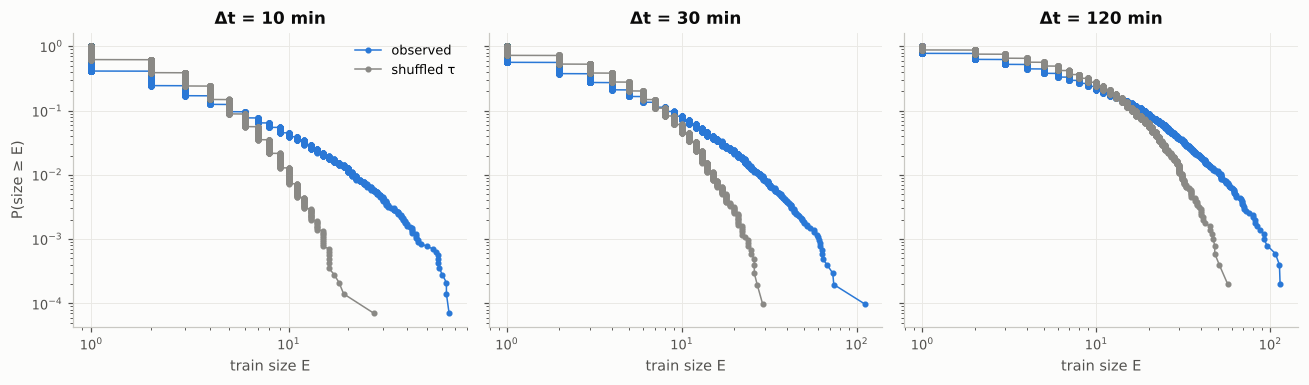

In [10]:
ts = PP.to_seconds(posts.t_utc)
rng = np.random.default_rng(1)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
rows = []
for a, w in zip(axes, [10, 30, 120]):
    E = PP.burst_sizes(ts, w * 60)
    tau_s = np.diff(np.sort(ts)); sh = np.concatenate([[0], np.cumsum(rng.permutation(tau_s))])
    Esh = PP.burst_sizes(sh, w * 60)
    for x, lab, col in [(E, "observed", C[0]), (Esh, "shuffled τ", PL.GREY)]:
        xs, ys = PP.ccdf(x); a.loglog(xs, ys, color=col, marker="o", ms=3, lw=1, label=lab)
    f = PP.fit_powerlaw(E, discrete=True, min_tail=30); PP.compare_tails(E, f)
    rows.append(dict(window_min=w, mean_E=E.mean(), max_E=E.max(), max_E_shuffled=Esh.max(), beta_E=f.alpha,
                     xmin=f.xmin, LR_vs_exp=f.lr_exponential[0], p=f.lr_exponential[1]))
    a.set_title(f"Δt = {w} min"); a.set_xlabel("train size E")
axes[0].set_ylabel("P(size ≥ E)"); axes[0].legend()
save(fig, "A3_bursty_trains"); display(pd.DataFrame(rows))

### A4. Long-range temporal correlations (DFA)
We use hourly counts with the mean weekly profile subtracted, so the daily cycle does not show up as spurious correlation. $\alpha_{DFA}=0.5$ means no memory, and $\alpha_{DFA}>0.5$ means persistent long-range correlations. A shuffled surrogate gives the null.

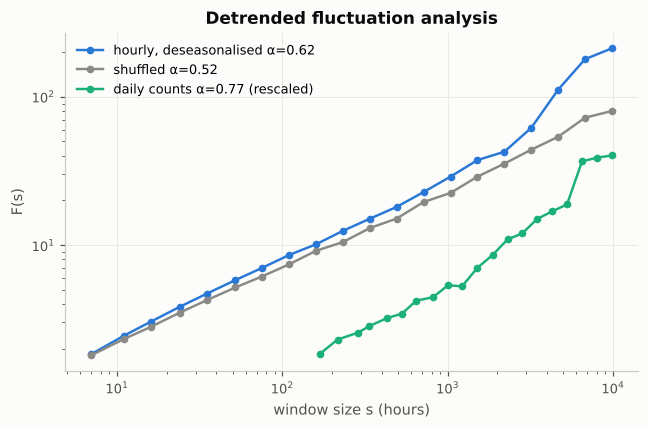

In [11]:
hourly = posts.set_index("t_et").resample("h").size()
how = hourly.index.dayofweek * 24 + hourly.index.hour
deseason = hourly - hourly.groupby(how).transform("mean")
s1, F1, a1 = PP.dfa(deseason.to_numpy())
s2, F2, a2 = PP.dfa(np.random.default_rng(0).permutation(deseason.to_numpy()))
s3, F3, a3 = PP.dfa(daily_all.to_numpy().astype(float))
fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(s1, F1, "o-", color=C[0], label=f"hourly, deseasonalised α={a1:.2f}")
ax.loglog(s2, F2, "o-", color=PL.GREY, label=f"shuffled α={a2:.2f}")
ax.loglog(s3 * 24, F3 * F1[0] / F3[0], "o-", color=C[2], label=f"daily counts α={a3:.2f} (rescaled)")
ax.set_xlabel("window size s (hours)"); ax.set_ylabel("F(s)"); ax.legend(); ax.set_title("Detrended fluctuation analysis")
save(fig, "A4_dfa");
SUMMARY.update(DFA_alpha_hourly=a1, DFA_alpha_daily=a3)

### A5. Self-exciting point process (Hawkes)
$$\lambda(t) = \mu\, s(t) + \sum_{t_i<t} \alpha\, e^{-\beta (t-t_i)}$$
The **branching ratio** $n=\alpha/\beta$ is the mean number of posts directly triggered by one post. It is the fraction of activity that is *endogenous*. $n\to1$ is the critical point, where activity becomes self-sustaining (Filimonov & Sornette 2012). An unmodelled seasonal baseline inflates $n$, so we compare a constant baseline with a **circadian** baseline $s(t)$ (the empirical hour-of-week profile). We check goodness of fit with the **time-rescaling theorem**: under the true model, compensator increments are i.i.d. Exp(1).

In [12]:
hk_c = PP.fit_hawkes(posts.t_et, circadian=False)
hk_s = PP.fit_hawkes(posts.t_et, circadian=True)
hk_tab = pd.DataFrame([dict(baseline=f.baseline, mu_per_hour=f.mu, branching_ratio=f.branching_ratio,
                            decay_minutes=60 / f.beta, loglik=f.loglik, AIC=f.aic()) for f in [hk_c, hk_s]]).set_index("baseline")
display(hk_tab)
res = PP.hawkes_residuals(hk_s)
ks = stats.kstest(res, "expon")
print(f"Time-rescaling KS test (circadian model): D={ks.statistic:.3f}, p={ks.pvalue:.3g}")
if DEMO:
    print("Planted values: n =", synthetic.TRUE_PARAMS["branching_ratio"], "decay =", synthetic.TRUE_PARAMS["decay_hours"] * 60, "min")
SUMMARY.update(hawkes_n_constant=hk_c.branching_ratio, hawkes_n_circadian=hk_s.branching_ratio,
               hawkes_decay_min=60 / hk_s.beta, hawkes_KS_D=ks.statistic)

,mu_per_hour,branching_ratio,decay_minutes,loglik,AIC
baseline,,,,,
constant,0.3911,0.5873,2.0700,14917.8033,-29829.6067
circadian,0.4024,0.5753,1.9418,17390.2593,-34774.5187


Time-rescaling KS test (circadian model): D=0.064, p=1.01e-134


**Two timescales.** On the real data a single exponential kernel decays in about 2 minutes, which captures rapid-fire *reposting sprees*. Its time-rescaling KS test rejects the fit. Human activity typically mixes several timescales, so we fit a **two-kernel Hawkes model**, $\alpha_1 e^{-\beta_1 t} + \alpha_2 e^{-\beta_2 t}$, with a total branching ratio of $\sum_k \alpha_k/\beta_k$. We fit it to all posts and to original-text posts only, and compare by AIC and KS.

In [13]:
hk_rows, hk_multi = [], {}
for name, sub in [("all posts", posts), ("original text only", orig)]:
    f1 = hk_s if name == "all posts" else PP.fit_hawkes(sub.t_et, circadian=True)
    f2 = PP.fit_hawkes_multi(sub.t_et, K=2, circadian=True)
    hk_multi[name] = f2
    ks1 = stats.kstest(PP.hawkes_residuals(f1), "expon").statistic
    ks2 = stats.kstest(PP.hawkes_multi_residuals(f2), "expon").statistic
    comp = f2.components
    hk_rows += [dict(data=name, model="1 kernel", n=f1.branching_ratio, fast_decay_min=60 / f1.beta, slow_decay_min=np.nan,
                     n_fast=f1.branching_ratio, n_slow=np.nan, AIC=f1.aic(), KS_D=ks1),
                dict(data=name, model="2 kernels", n=f2.branching_ratio, fast_decay_min=comp.decay_minutes[0],
                     slow_decay_min=comp.decay_minutes[1], n_fast=comp.branching_ratio[0], n_slow=comp.branching_ratio[1],
                     AIC=f2.aic(), KS_D=ks2)]
hk2_tab = pd.DataFrame(hk_rows).set_index(["data", "model"])
display(hk2_tab.round(3))
f2 = hk_multi["all posts"]
SUMMARY.update(hawkes2_n=f2.branching_ratio, hawkes2_fast_min=f2.components.decay_minutes[0],
               hawkes2_slow_min=f2.components.decay_minutes[1], hawkes2_n_original=hk_multi["original text only"].branching_ratio)

n  fast_decay_min  slow_decay_min  n_fast  n_slow        AIC   KS_D
data               model                                                                             
all posts          1 kernel   0.575           1.942             NaN   0.575     NaN -34774.519  0.064
                   2 kernels  0.662           1.022          14.521   0.431   0.231 -38803.233  0.049
original text only 1 kernel   0.427           5.634             NaN   0.427     NaN  32037.205  0.043
                   2 kernels  0.496           1.670          21.029   0.224   0.272  30645.048  0.030

,count,mean,std,min,25%,50%,75%,max
n_events,52.0,2061.0385,620.0947,866.0000,1612.5000,1865.5000,2570.7500,3400.0000
branching_ratio,52.0,0.5501,0.0679,0.3941,0.5084,0.5540,0.6057,0.6549
decay_min,52.0,2.0039,0.8103,0.9407,1.5111,1.8654,2.3544,5.2831


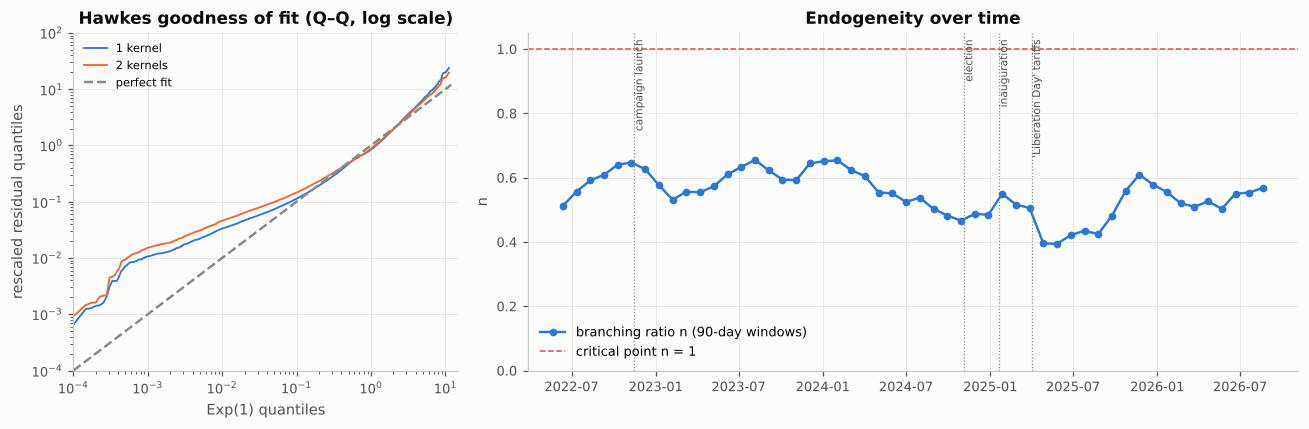

In [14]:
roll = PP.rolling_hawkes(posts.t_et, window="90D", step="30D" if not FAST else "60D", circadian=True)
fig, ax = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw=dict(width_ratios=[1, 2]))
for lab, rr, col in [("1 kernel", res, C[0]), ("2 kernels", PP.hawkes_multi_residuals(hk_multi["all posts"]), C[1])]:
    q = np.sort(rr); th = stats.expon.ppf((np.arange(1, len(q) + 1) - 0.5) / len(q))
    ax[0].loglog(th, q, color=col, lw=1.2, label=lab)
ax[0].loglog([1e-4, 12], [1e-4, 12], "--", color=PL.GREY, label="perfect fit")
ax[0].set_xlim(1e-4, 15); ax[0].set_ylim(1e-4, 100); ax[0].legend(fontsize=7.5)
ax[0].set_xlabel("Exp(1) quantiles"); ax[0].set_ylabel("rescaled residual quantiles"); ax[0].set_title("Hawkes goodness of fit (Q–Q, log scale)")
ax[1].plot(roll["mid"], roll["branching_ratio"], "o-", color=C[0], label="branching ratio n (90-day windows)")
ax[1].axhline(1, color=C[7], ls="--", lw=1, label="critical point n = 1")
ax[1].set_ylim(0, 1.05); ax[1].set_ylabel("n"); ax[1].legend(loc="lower left"); ax[1].set_title("Endogeneity over time")
for d, lab in KEY_DATES.items():
    ax[1].axvline(pd.Timestamp(d, tz=D.ET), color=PL.GREY, lw=0.8, ls=":")
    ax[1].text(pd.Timestamp(d, tz=D.ET), 1.03, lab, fontsize=7, rotation=90, va="top", color=PL.INK2)
save(fig, "A5_hawkes"); display(roll[["mid", "n_events", "branching_ratio", "decay_min"]].describe().T)
SUMMARY.update(hawkes_n_rolling_min=roll.branching_ratio.min(), hawkes_n_rolling_max=roll.branching_ratio.max())

#### Findings A: a bursty, self-exciting, sub-critical process
* **Bursty.** The mean gap between posts is 63 minutes, but the median is only 2.8 minutes. Burstiness is $B=0.45$ (a Poisson process gives 0). It stays at 0.41 after time is rescaled by his weekly activity profile, so **the burstiness is not just the day/night cycle**. Consecutive gaps are correlated ($M_{\log}=0.41$): short gaps follow short gaps.
* **Heavy-tailed, but not a power law.** The gap distribution is far from exponential. The CSN test rejects a pure power law ($p_{gof}=0.005$), and a **lognormal** fits the tail better (LR = −2.6, p = 0.008). This mirrors other human activity data, where heavy tails often come from mixtures of timescales rather than a single scale-free mechanism.
* **Correlated bursts.** With Δt = 30 min, the largest bursty train holds 111 posts, against 29 when the same gaps are shuffled. Bursts are *clustered*, which independent gaps cannot produce (Karsai et al. 2012).
* **Long memory.** The DFA exponent is α = 0.62 on deseasonalised hourly counts and 0.77 on daily counts, where 0.5 means no memory. Activity is persistent across hours and weeks.
* **Self-excitation.** A circadian-baseline Hawkes model gives a branching ratio of $n = 0.58$, with triggering that decays in about 2 minutes. That fit is rejected by the time-rescaling test. A **two-timescale kernel** fits far better (ΔAIC ≈ 4,000) and gives $n = 0.66$: $n=0.43$ from ~1-minute *posting sprees* plus $n=0.23$ from ~15-minute *follow-ups*. On original posts only, $n = 0.50$. About half to two-thirds of his activity is therefore **endogenous**, generated by his own previous posts.
* **Sub-critical throughout.** The rolling branching ratio stays between 0.39 and 0.65 and never approaches the critical value $n=1$. It **dips to 0.39 right after the April 2025 'Liberation Day' tariffs**, when his posting was most driven by outside events. The system sits in a stable, sub-critical regime: activity bursts but always dies out.

## Part B. Attention and language
### B1. Heavy-tailed engagement
Engagement counts in the archive are snapshots. We drop the last 7 days, where counts are still growing.

,alpha,alpha_se,xmin,n_tail,KS,p_gof,LR_vs_lognormal,p_LR_lognormal,LR_vs_exponential,p_LR_exponential
favourites_count,5.2631,0.1742,47277.0,599.0,0.0288,0.88,-0.0765,0.9390,1.9524,0.0509
reblogs_count,4.7405,0.1267,10697.0,871.0,0.0325,0.04,-0.7080,0.4790,1.2840,0.1991
replies_count,3.5039,0.0848,3984.0,871.0,0.0283,0.22,-1.1839,0.2364,2.2954,0.0217


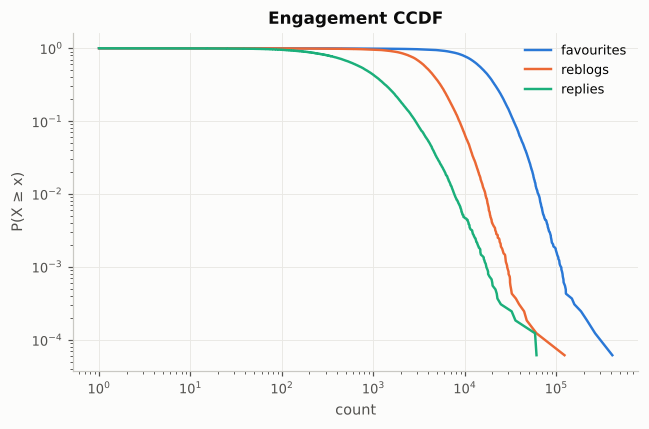

In [15]:
eng = orig[orig.t_utc < orig.t_utc.max() - pd.Timedelta("7D")]
fits, fig = {}, plt.figure(figsize=(6, 4)); ax = fig.gca()
for i, col in enumerate(["favourites_count", "reblogs_count", "replies_count"]):
    x = eng[col].dropna().to_numpy(); x = x[x > 0]
    f = PP.fit_powerlaw(x, discrete=True); PP.compare_tails(x, f); PP.powerlaw_pvalue(x, f, n_boot=max(20, N_BOOT // 4))
    fits[col] = f.summary()
    xs, ys = PP.ccdf(x); ax.loglog(xs, ys, color=C[i], label=col.replace("_count", ""))
ax.set_xlabel("count"); ax.set_ylabel("P(X ≥ x)"); ax.legend(); ax.set_title("Engagement CCDF")
save(fig, "B1_engagement_ccdf"); display(pd.DataFrame(fits).T)

Which content attracts attention? We regress $\log(1+\text{favourites})$ on content features with **month fixed effects**, which absorb follower growth and platform changes. Standard errors are HC1-robust.

In [16]:
X = pd.DataFrame({"caps_ratio": eng.caps_ratio, "exclamations": eng.n_excl.clip(0, 10), "sentiment": eng.sent,
                  "abs_sentiment": eng.sent.abs(), "log_words": np.log1p(eng.n_words), "has_media": eng.media.map(lambda m: len(m) > 0 if isinstance(m, list) else bool(m)).astype(float),
                  **{c.replace("topic_", "T_"): eng[c].astype(float) for c in eng if c.startswith("topic_")}})
y = np.log1p(eng.favourites_count)
ok_rows = X.notna().all(axis=1) & y.notna()          # some archive rows have missing engagement counts
X, y = X[ok_rows].astype(float), y[ok_rows]
month = eng.t_et[ok_rows].dt.tz_localize(None).dt.to_period("M")
print(f"regression on {len(y):,} posts ({(~ok_rows).sum()} dropped for missing values)")
Xd = X - X.groupby(month.values).transform("mean"); yd = y - y.groupby(month.values).transform("mean")
keep = Xd.std() > 0; Xd = Xd.loc[:, keep]
beta, *_ = np.linalg.lstsq(Xd.values, yd.values, rcond=None)
e = yd.values - Xd.values @ beta
XtX_inv = np.linalg.pinv(Xd.values.T @ Xd.values)
V = XtX_inv @ (Xd.values.T * e ** 2) @ Xd.values @ XtX_inv * len(e) / (len(e) - Xd.shape[1] - month.nunique())
coef = pd.DataFrame({"coef": beta, "se": np.sqrt(np.diag(V))}, index=Xd.columns)
coef["t"] = coef.coef / coef.se; coef["pct_effect"] = (np.exp(coef.coef) - 1) * 100
display(coef.sort_values("t"))

regression on 16,354 posts (9 dropped for missing values)


,coef,se,t,pct_effect
T_endorsement,-0.4727,0.0257,-18.3853,-37.6691
T_energy,-0.2396,0.0276,-8.6710,-21.3069
T_markets_economy,-0.1206,0.0172,-6.9917,-11.3597
sentiment,-0.0466,0.0082,-5.6599,-4.5522
T_immigration,-0.1054,0.0211,-5.0028,-10.0006
T_elections,-0.0551,0.0116,-4.7484,-5.3601
has_media,-0.0289,0.0112,-2.5862,-2.8503
T_crypto,-0.2090,0.0927,-2.2539,-18.8565
T_legal,-0.0229,0.0138,-1.6569,-2.2641
T_media_attack,0.0307,0.0244,1.2560,3.1141


### B2. Linguistic laws: Zipf and Heaps

Most frequent content words: ['that', 'will', 'this', 'great', 'trump', 'with', 'have', 'they', 'president', 'america', 'people', 'from', 'country', 'very', 'election', 'never', 'american', 'biden', 'state', 'your', 'states', 'just', 'been', 'united', 'donald']


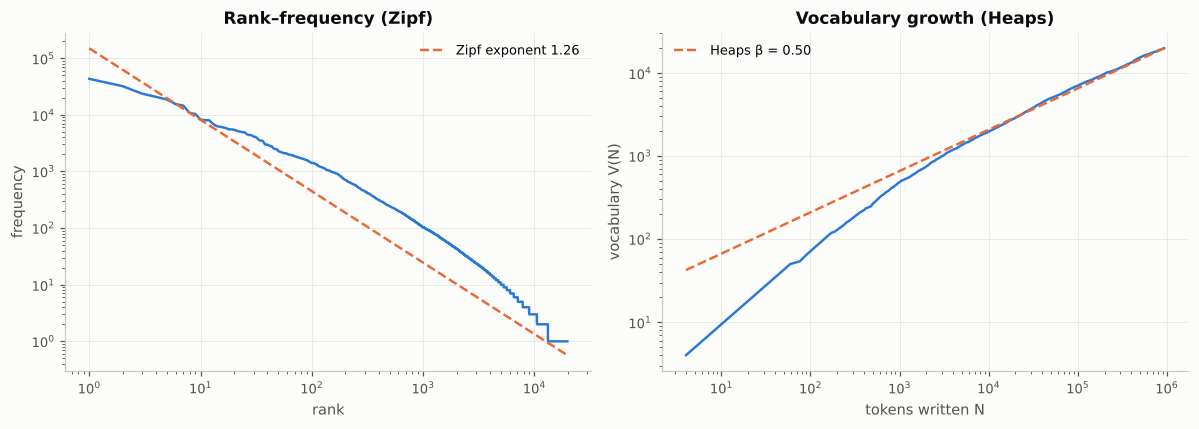

In [17]:
toks = [TX.tokens(t) for t in orig.text_nourl]
ranks, freq, z_exp, counter = PP.zipf(toks)
Nh, Vh, heaps_beta = PP.heaps(toks)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].loglog(ranks, freq, color=C[0]); ax[0].loglog(ranks, freq[9] * (ranks / 10) ** (-z_exp), "--", color=C[1], label=f"Zipf exponent {z_exp:.2f}")
ax[0].set_xlabel("rank"); ax[0].set_ylabel("frequency"); ax[0].legend(); ax[0].set_title("Rank–frequency (Zipf)")
ax[1].loglog(Nh, Vh, color=C[0]); ax[1].loglog(Nh, Vh[-1] * (Nh / Nh[-1]) ** heaps_beta, "--", color=C[1], label=f"Heaps β = {heaps_beta:.2f}")
ax[1].set_xlabel("tokens written N"); ax[1].set_ylabel("vocabulary V(N)"); ax[1].legend(); ax[1].set_title("Vocabulary growth (Heaps)")
save(fig, "B2_zipf_heaps"); SUMMARY.update(zipf_exponent=z_exp, heaps_beta=heaps_beta)
print("Most frequent content words:", [w for w, _ in counter.most_common(80) if len(w) > 3][:25])

### B3. Amplification: whose voices does he repost?
About 1 in 5 posts is a ReTruth. Which accounts get amplified is itself a complex system. Attention is very unequal across accounts, so we fit the distribution of reposts per account (CSN). Is the inequality produced by **preferential attachment**, i.e. is an account more likely to be reposted again the more it has been reposted already? We estimate the attachment kernel $\Pi(k)\propto k^{\gamma}$ (Jeong, Néda & Barabási 2003): each month, the reposts that accounts with $k$ earlier reposts receive, per such account. $\gamma=1$ is linear preferential attachment (it gives power laws), $\gamma<1$ is sublinear (lognormal-like), and $\gamma=0$ means no rich-get-richer.

7,508 ReTruths of 1,017 accounts; self-reposts 39.2%; Gini (other accounts) = 0.73; top-10 accounts get 35% of reposts


,reposts
repost_of,
rsbn,360
teamtrump,330
realamericasvoice,308
marklevinshow,124
godandcountryy,95
danscavino,91
mrddmia,88
iapolls2022,76
newsmax,70


reposts-per-account tail: {'alpha': 1.728, 'alpha_se': 0.045, 'xmin': 2.0, 'n_tail': 260, 'KS': 0.035, 'p_gof': None, 'LR_vs_lognormal': -16.031, 'p_LR_lognormal': 0.0, 'LR_vs_exponential': 3.405, 'p_LR_exponential': 0.001}


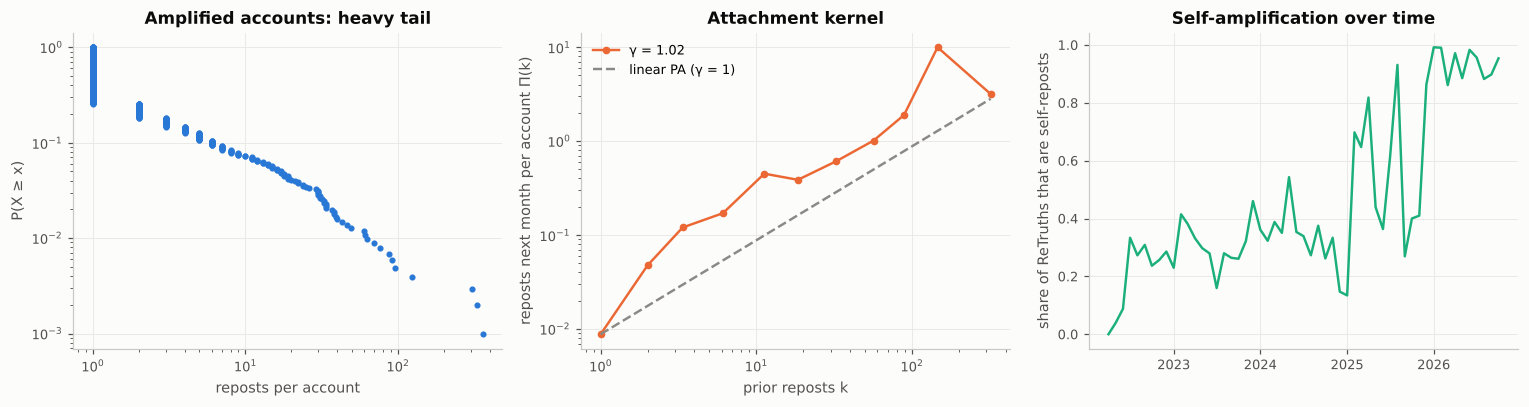

In [18]:
rp = posts[posts.is_repost & posts.repost_of.notna()].copy()
cnt = rp.repost_of.value_counts()
others = cnt.drop("realdonaldtrump", errors="ignore")
gini = lambda x: (np.sort(x) * (2 * np.arange(1, len(x) + 1) - len(x) - 1)).sum() / (len(x) * np.sum(x))
print(f"{len(rp):,} ReTruths of {cnt.size:,} accounts; self-reposts {rp.is_self_repost.mean():.1%}; "
      f"Gini (other accounts) = {gini(others.values):.2f}; top-10 accounts get {others.head(10).sum() / others.sum():.0%} of reposts")
display(others.head(15).to_frame("reposts"))
f_rp = PP.fit_powerlaw(others.values, discrete=True, min_tail=30); PP.compare_tails(others.values, f_rp)
print("reposts-per-account tail:", {k: (round(v, 3) if isinstance(v, float) else v) for k, v in f_rp.summary().items()})
# attachment kernel, monthly
rp["month"] = rp.t_et.dt.tz_localize(None).dt.to_period("M")
rp_o = rp[~rp.is_self_repost]
months = sorted(rp_o.month.unique()); prior = pd.Series(dtype=float); rows = []
for m in months:
    new = rp_o[rp_o.month == m].repost_of.value_counts()
    if len(prior):
        k = prior[prior > 0]
        rows.append(pd.DataFrame({"k": k.values, "gain": new.reindex(k.index).fillna(0).values}))
    prior = prior.add(new, fill_value=0)
att = pd.concat(rows)
bins = np.unique(np.round(np.logspace(0, np.log10(att.k.max() + 1), 12)))
att["kb"] = pd.cut(att.k, np.append(bins, np.inf), right=False, labels=bins)
kern = att.groupby("kb", observed=True).agg(k=("k", "mean"), Pi=("gain", "mean"), n=("gain", "size"))
kern = kern[(kern.n >= 5) & (kern.Pi > 0)]
gamma_pa = np.polyfit(np.log(kern.k), np.log(kern.Pi), 1)[0]
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
xs, ys = PP.ccdf(others.values); ax[0].loglog(xs, ys, "o", ms=3, color=C[0]); ax[0].set_xlabel("reposts per account"); ax[0].set_ylabel("P(X ≥ x)")
ax[0].set_title("Amplified accounts: heavy tail")
ax[1].loglog(kern.k, kern.Pi, "o-", color=C[1], label=f"γ = {gamma_pa:.2f}")
ax[1].loglog(kern.k, kern.Pi.iloc[0] * (kern.k / kern.k.iloc[0]), "--", color=PL.GREY, label="linear PA (γ = 1)")
ax[1].set_xlabel("prior reposts k"); ax[1].set_ylabel("reposts next month per account Π(k)"); ax[1].legend(); ax[1].set_title("Attachment kernel")
ms = rp.groupby("month").is_self_repost.mean(); ax[2].plot(ms.index.to_timestamp(), ms.values, color=C[2])
ax[2].set_ylabel("share of ReTruths that are self-reposts"); ax[2].set_title("Self-amplification over time")
import matplotlib.dates as mdates
ax[2].xaxis.set_major_locator(mdates.YearLocator()); ax[2].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
save(fig, "B3_amplification")
SUMMARY.update(repost_gini=gini(others.values), repost_self_share=rp.is_self_repost.mean(), attachment_gamma=gamma_pa)

#### Findings B: heavy-tailed attention and rich-get-richer amplification
* **Engagement is heavy-tailed.** The favourites tail above about 47k is consistent with a steep power law (α = 5.3, $p_{gof}=0.88$), though a lognormal fits equally well. Replies and reblogs are similar.
* **What attracts attention.** These regression effects use month fixed effects, which absorb follower growth:
  * an all-caps post gets **+29%** likes; each exclamation mark +6.6%; emotional intensity (|sentiment|) +12.6% per unit;
  * tariff posts **+22%**; war and foreign-affairs posts **+16%**;
  * candidate **endorsements −38%** and energy posts −21%.

  The audience rewards conflict and intensity.
* **Linguistic laws.** The rank-frequency exponent is 1.26, steeper than Zipf's 1, and the Heaps exponent is β = 0.50. That is a **small, highly repetitive vocabulary**, typical of slogan-driven speech.
* **Amplification.** 7,508 ReTruths go to 1,017 accounts. They are highly concentrated (Gini 0.73; the top 10 accounts get 35%), and the share of **self-reposts rose from about 30% (2022–24) to about 90% in 2026**. The attachment kernel is **linear**: Π(k) ∝ k^1.02. An account's chance of being reposted again grows in proportion to how often it has already been reposted. This is the textbook Barabási–Albert *rich-get-richer* mechanism, observed directly in one person's amplification choices. The finite observation window makes the resulting distribution lognormal-like rather than a pure power law (LR vs lognormal = −16).

## Part C. The network of attention
Nodes are the entities he talks about: people, countries, institutions, media, companies, and frequent @handles. An edge means two entities appear in the same post, weighted by the number of such posts.
### C1–C2. Global structure vs null models

,value
nodes,99.0000
edges,820.0000
density,0.1690
gcc_frac,0.9798
mean_degree,16.5657
clustering,0.6868
weighted_clustering,0.0181
transitivity,0.4569
assortativity,-0.2779
avg_path_gcc,1.9680


strength tail: {'alpha': 2.609, 'alpha_se': 0.369, 'xmin': 386.0, 'n_tail': 19, 'KS': 0.065, 'p_gof': None, 'LR_vs_lognormal': -0.469, 'p_LR_lognormal': 0.639, 'LR_vs_exponential': 1.05, 'p_LR_exponential': 0.294}


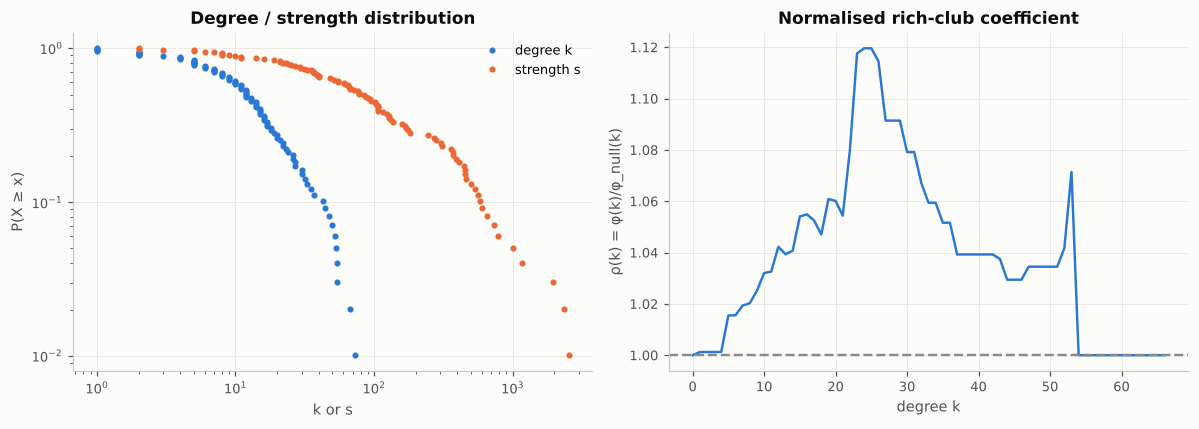

In [19]:
G = NW.comention_graph(orig.entities.tolist(), min_node_count=10, min_edge_weight=2)
st = NW.basic_stats(G); sw = NW.small_world(G, n_null=max(3, N_NULL_NET // 3))
display(pd.Series({**st, **{f"sw_{k}": v for k, v in sw.items()}}).to_frame("value"))
strength = np.array([d for _, d in G.degree(weight="weight")])
f_s = PP.fit_powerlaw(strength, discrete=True, min_tail=15); PP.compare_tails(strength, f_s)
print("strength tail:", {k: round(v, 3) if isinstance(v, float) else v for k, v in f_s.summary().items()})
rc = NW.rich_club(G, n_null=max(3, N_NULL_NET // 3))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for x, lab, col in [(np.array([d for _, d in G.degree()]), "degree k", C[0]), (strength, "strength s", C[1])]:
    xs, ys = PP.ccdf(x); ax[0].loglog(xs, ys, "o", ms=3, color=col, label=lab)
ax[0].set_xlabel("k or s"); ax[0].set_ylabel("P(X ≥ x)"); ax[0].legend(); ax[0].set_title("Degree / strength distribution")
ax[1].plot(rc.k, rc.rho, color=C[0]); ax[1].axhline(1, ls="--", color=PL.GREY)
ax[1].set_xlabel("degree k"); ax[1].set_ylabel("ρ(k) = φ(k)/φ_null(k)"); ax[1].set_title("Normalised rich-club coefficient")
save(fig, "C1_degree_richclub")
SUMMARY.update(net_nodes=st["nodes"], net_edges=st["edges"], small_world_sigma=sw["sigma"], assortativity=st["assortativity"])

### C3–C4. Backbone, centrality and communities
The **disparity filter** keeps only edges whose weight is statistically significant given each node's strength, with α = 0.05. Communities come from Louvain. Its modularity $Q$ is compared with $Q$ found on degree-preserving, weight-shuffled **null networks**, because modularity is non-zero even for random graphs (Guimerà et al. 2004). We also check robustness across seeds (mean NMI) and agreement with other algorithms.

In [20]:
BB = NW.disparity_filter(G, alpha=0.05)
print(f"backbone keeps {BB.number_of_edges()}/{G.number_of_edges()} edges ({BB.number_of_edges()/G.number_of_edges():.0%}) "
      f"and {BB.number_of_nodes()}/{G.number_of_nodes()} nodes, but {sum(d['weight'] for *_, d in BB.edges(data=True))/sum(d['weight'] for *_, d in G.edges(data=True)):.0%} of total weight")
cent = NW.centralities(G); display(cent.head(15))
comms, part, Q = NW.louvain(G)
msig = NW.modularity_significance(G, n_null=N_NULL_NET)
stab = NW.partition_stability(G, n_runs=10 if FAST else 30)
print(f"Weighted Louvain Q = {Q:.3f}. Topology test (unweighted): Q = {msig['Q']:.3f} vs degree-preserving null "
      f"{msig['Q_null_mean']:.3f} ± {msig['Q_null_sd']:.3f} (z = {msig['z']:.1f}); seed stability NMI = {stab:.2f}")
display(NW.compare_algorithms(G))
for i, c in enumerate(comms[:8]):
    top = sorted(c, key=lambda n: -G.nodes[n]["count"])[:10]
    print(f"community {i} ({len(c)} nodes):", ", ".join(top))
SUMMARY.update(modularity_Q_weighted=Q, modularity_Q_unweighted=msig["Q"], modularity_z=msig["z"], n_communities=len(comms), partition_stability_NMI=stab)

backbone keeps 81/820 edges (10%) and 51/99 nodes, but 49% of total weight


,degree,strength,betweenness,eigenvector,pagerank,core_number
Democrats,73,2539.0,0.5504,0.5382,0.0915,15
Joe Biden,67,2362.0,0.5716,0.4034,0.0850,15
Republicans,52,1967.0,0.1010,0.4900,0.0662,15
MAGA,54,1163.0,0.1147,0.2896,0.0390,15
Russia,53,782.0,0.1212,0.0980,0.0344,15
Congress,43,998.0,0.0589,0.2884,0.0343,15
China,54,603.0,0.2443,0.0870,0.0290,15
Fake News Media,44,734.0,0.1334,0.1116,0.0282,15
Iran,50,538.0,0.0688,0.0640,0.0249,15
DOJ,33,657.0,0.0000,0.1410,0.0230,15


Weighted Louvain Q = 0.340. Topology test (unweighted): Q = 0.233 vs degree-preserving null 0.132 ± 0.005 (z = 18.8); seed stability NMI = 0.94


,algorithm,n_comms,Q,NMI_vs_louvain
0,louvain,7,0.3403,1.0000
1,greedy_modularity,8,0.3429,0.8918
2,label_propagation,3,0.1587,0.3213


community 0 (41 nodes): Iran, China, Russia, Ukraine, Israel, Canada, Venezuela, Afghanistan, Mexico, Vladimir Putin
community 1 (21 nodes): Democrats, Republicans, MAGA, Congress, Fox News, Ron DeSantis, Supreme Court, Nikki Haley, Mitch McConnell, Nancy Pelosi
community 2 (14 nodes): Joe Biden, Kamala Harris, DOJ, FBI, Jack Smith, Hillary Clinton, Barack Obama, Letitia James, Alvin Bragg, Fani Willis
community 3 (14 nodes): Fake News Media, CNN, New York Times, ABC, MSNBC, Elon Musk, CBS, Truth Social, NBC, Washington Post
community 4 (5 nodes): @rsbn, @realamericasvoice, @newsmax, @rumble, @oan
community 5 (2 nodes): Viktor Orban, Hungary
community 6 (2 nodes): Federal Reserve, Jerome Powell


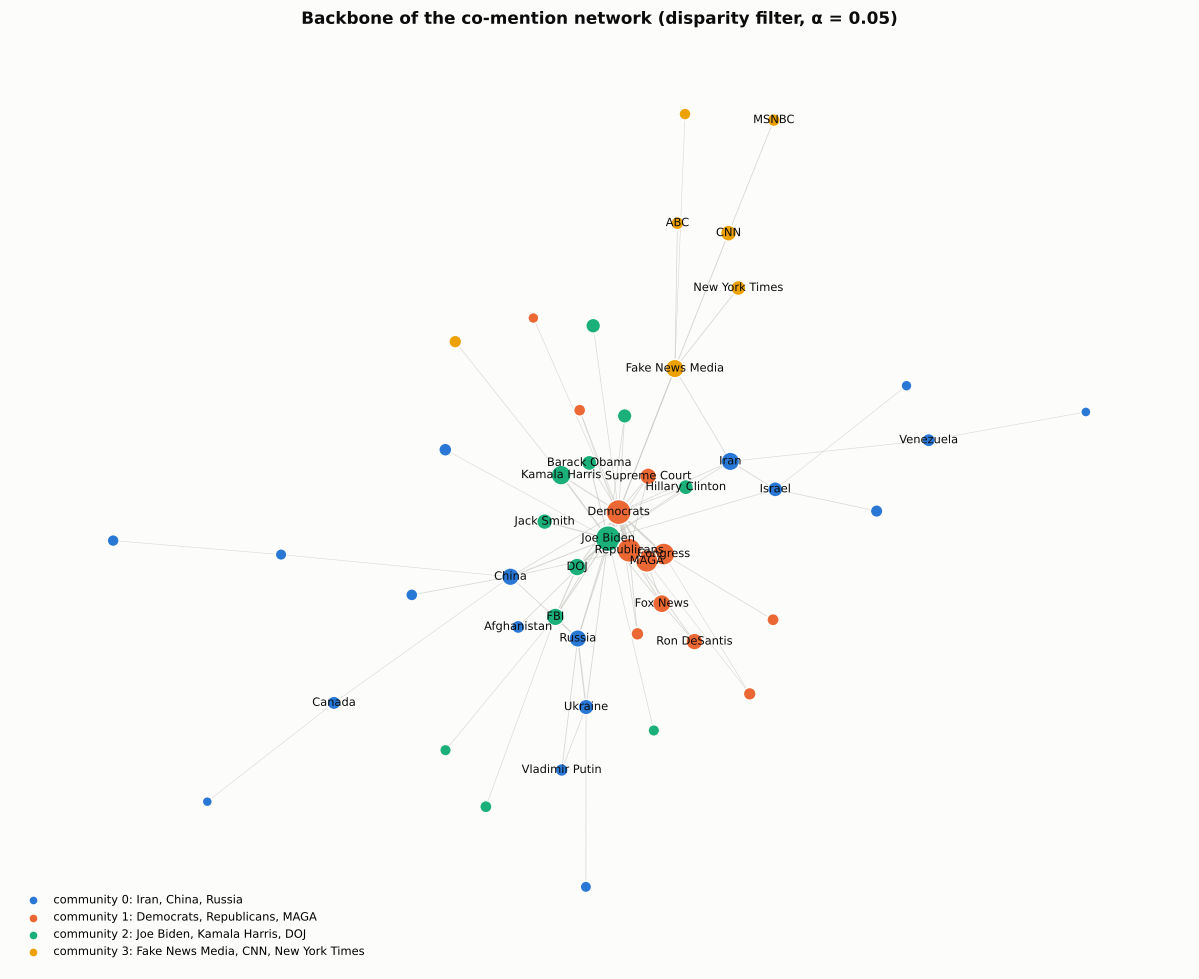

In [21]:
H = BB.subgraph(max(nx.connected_components(BB), key=len)).copy() if BB.number_of_edges() else nx.Graph()
if H.number_of_nodes() < 20:   # backbone too sparse to show -> draw the full graph's strongest edges instead
    print("backbone GCC small; drawing the full graph's top-25% edges instead")
    wq = np.quantile([d["weight"] for *_, d in G.edges(data=True)], 0.75)
    H = nx.Graph([(u, v, d) for u, v, d in G.edges(data=True) if d["weight"] >= wq])
pos = nx.spring_layout(H, weight="weight", seed=3, k=1.2 / np.sqrt(H.number_of_nodes()), iterations=200)
fig, ax = plt.subplots(figsize=(11, 9)); ax.axis("off")
w = np.array([H[u][v]["weight"] for u, v in H.edges()])
nx.draw_networkx_edges(H, pos, width=0.3 + 2.5 * w / w.max(), edge_color="#c9c8c3", alpha=0.7, ax=ax)
cols = [C[part[n]] if part.get(n, 99) < 8 else PL.GREY for n in H]
sizes = [20 + 6 * np.sqrt(G.nodes[n]["count"]) for n in H]
nx.draw_networkx_nodes(H, pos, node_color=cols, node_size=sizes, edgecolors="#fcfcfb", linewidths=1, ax=ax)
top_nodes = set(cent.index[:35]) & set(H)
nx.draw_networkx_labels(H, pos, labels={n: n for n in top_nodes}, font_size=7.5, font_color=PL.INK, ax=ax)
for i in range(min(8, len(comms))):
    if not set(comms[i]) & set(H): continue   # legend only for communities visible in the backbone
    ax.scatter([], [], color=C[i], label=f"community {i}: " + ", ".join(sorted(comms[i], key=lambda n: -G.nodes[n]['count'])[:3]))
ax.legend(loc="lower left", fontsize=7.5); ax.set_title("Backbone of the co-mention network (disparity filter, α = 0.05)")
save(fig, "C3_backbone_network");

### C5. Temporal network: how his world re-wires
Quarterly snapshots. We track edge persistence (Jaccard overlap with the previous quarter), the stability of community structure (NMI on shared nodes), and the PageRank trajectories of the most central actors.

,nodes,edges,density,clustering,Q,n_comms,edge_jaccard,node_jaccard,NMI_prev
period,,,,,,,,,
2022-04-01,23,54,0.213,0.681,0.479,3,NaN,NaN,NaN
2022-07-01,37,121,0.182,0.679,0.452,4,0.296,0.538,0.507
2022-10-01,39,138,0.186,0.648,0.441,4,0.315,0.767,0.491
2023-01-01,33,163,0.309,0.673,0.250,3,0.326,0.600,0.520
2023-04-01,28,141,0.373,0.727,0.142,3,0.345,0.488,0.327
2023-07-01,33,156,0.295,0.728,0.141,4,0.394,0.525,0.543
2023-10-01,42,223,0.259,0.777,0.302,4,0.368,0.705,0.368
2024-01-01,45,198,0.200,0.620,0.354,6,0.413,0.706,0.428
2024-04-01,37,168,0.252,0.740,0.313,4,0.366,0.673,0.568


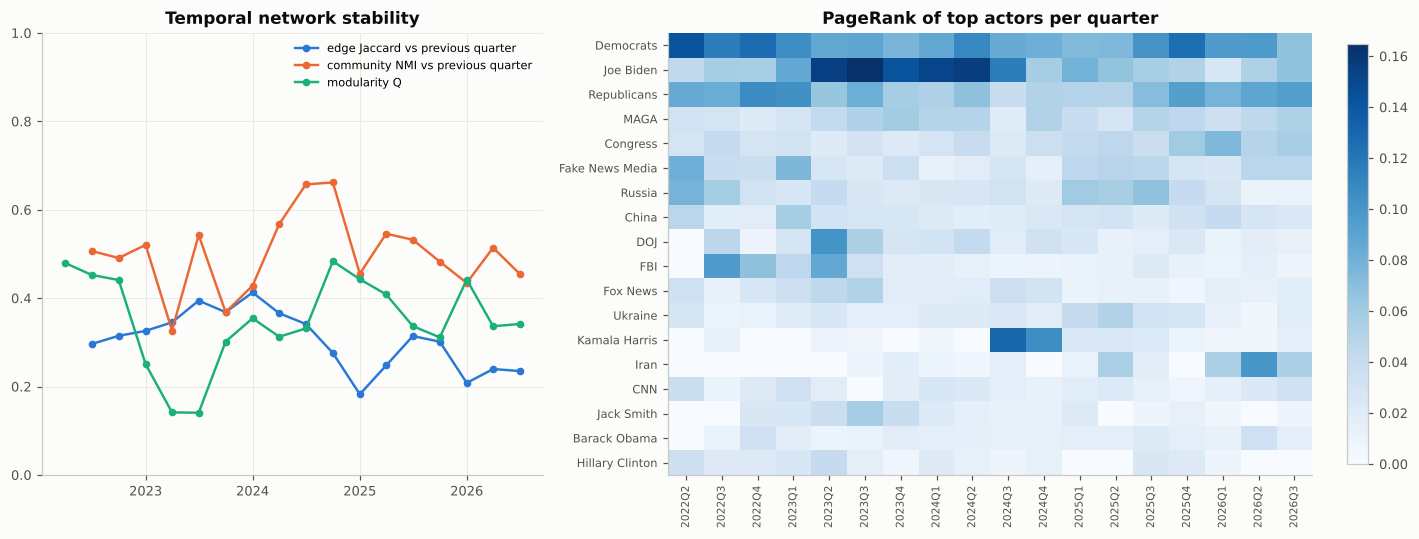

In [22]:
snaps = NW.temporal_snapshots(orig, freq="QS", min_node_count=3, min_edge_weight=1)
last_post = orig.t_et.max().tz_localize(None)
snaps = {k: v for k, v in snaps.items() if k + pd.offsets.QuarterEnd(0) <= last_post}  # drop the incomplete quarter
tm = NW.temporal_metrics(snaps); display(tm.round(3))
traj = NW.centrality_trajectories(snaps, top=18)
fig, ax = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw=dict(width_ratios=[1, 1.4]))
ax[0].plot(tm.index, tm.edge_jaccard, "o-", color=C[0], label="edge Jaccard vs previous quarter")
ax[0].plot(tm.index, tm.NMI_prev, "o-", color=C[1], label="community NMI vs previous quarter")
ax[0].plot(tm.index, tm.Q, "o-", color=C[2], label="modularity Q")
ax[0].set_ylim(0, 1); ax[0].legend(fontsize=7.5); ax[0].set_title("Temporal network stability")
import matplotlib.dates as mdates
ax[0].xaxis.set_major_locator(mdates.YearLocator()); ax[0].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
im = ax[1].imshow(traj.values, aspect="auto", cmap="Blues")
ax[1].set_yticks(range(len(traj)), traj.index, fontsize=7.5)
ax[1].set_xticks(range(len(traj.columns)), [f"{c:%Y}Q{(c.month-1)//3+1}" for c in traj.columns], rotation=90, fontsize=7)
ax[1].grid(False); ax[1].set_title("PageRank of top actors per quarter"); plt.colorbar(im, ax=ax[1], fraction=0.03)
save(fig, "C5_temporal_network");
SUMMARY.update(mean_edge_jaccard=tm.edge_jaccard.mean(), mean_community_NMI=tm.NMI_prev.mean())

### C6. Whom he praises and whom he attacks
For each actor, the mean sentiment of the sentences that name it, using own-voice posts only. This is the *valence* of each node in his attention network.

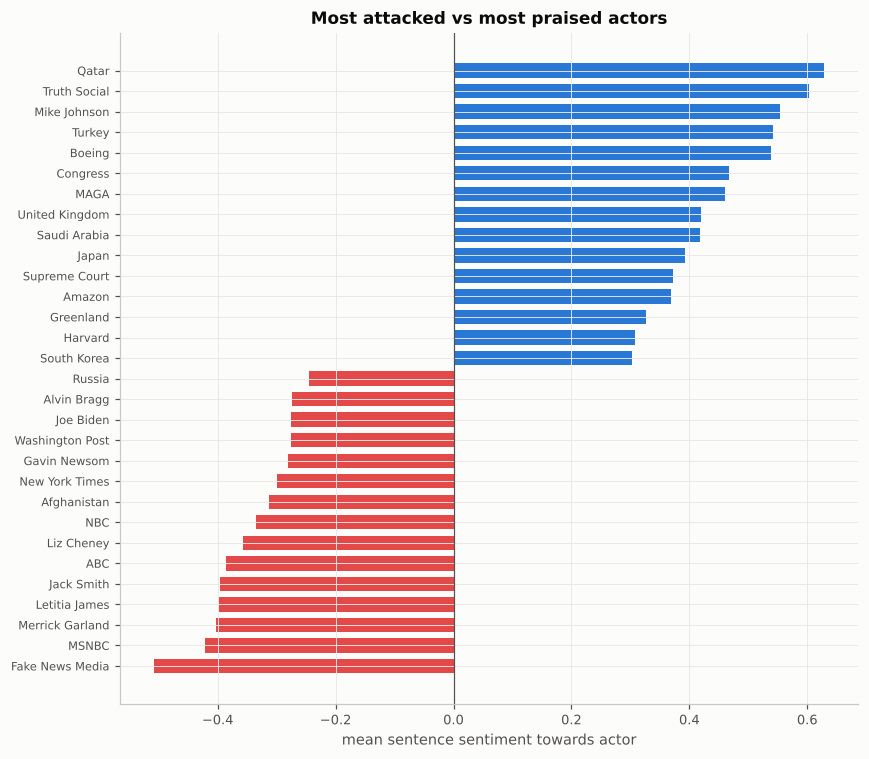

In [23]:
val = NW.entity_valence(own, min_count=15)
sel = pd.concat([val.head(15), val.tail(15)])
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(sel.index, sel.valence, color=[PL.DIVERGING[2] if v < 0 else PL.DIVERGING[0] for v in sel.valence], height=0.7)
ax.axvline(0, color=PL.INK2, lw=0.8); ax.set_xlabel("mean sentence sentiment towards actor")
ax.set_title("Most attacked vs most praised actors"); ax.tick_params(axis="y", labelsize=7.5)
save(fig, "C6_valence");

#### Findings C: a hub-and-spoke world that rewires quickly
* **Structure.** The network has 99 actors and 820 ties, with a mean shortest path of 1.97. Clustering is 0.70, against 0.59 in degree-preserving nulls, giving a small-world coefficient σ = 1.16 (weak). It is strongly **disassortative** (r = −0.28): a few hubs (Democrats, Biden, Republicans, MAGA, Congress, Russia, China) connect to many peripheral actors, a hub-and-spoke pattern. A **rich club** exists but is mild: ρ(k) peaks at about 1.12 for k ≈ 23–26, so the hubs are somewhat more interconnected than chance.
* **Backbone.** The disparity filter keeps only 10% of the ties, but they carry **49% of the total weight**. His attention is concentrated on a few significant links.
* **Communities are real and robust.** Louvain finds 7 communities. Topological modularity is Q = 0.233, against 0.132 ± 0.005 in nulls (z = 19). The partition is stable across seeds (NMI 0.94) and agrees with greedy modularity (NMI 0.89). The communities are meaningful:
  * **foreign affairs** (41 nodes);
  * **parties, Congress and the primaries** (Democrats, Republicans, MAGA, DeSantis, Haley, Fox News);
  * **legal cases** (Biden, DOJ, FBI, Jack Smith, Bragg, James, Willis);
  * **media and platforms** (Fake News Media, CNN, NYT, the networks, Musk, Truth Social);
  * **alt-media accounts** (RSBN, Newsmax, OAN, Rumble);
  * **Hungary/Orbán**;
  * **the Fed**.
* **Fast rewiring.** On average only **30% of ties persist** from one quarter to the next, and community membership is only partly preserved (NMI 0.50). PageRank shows the hubs taking turns: Biden peaks from 2023Q2 to 2024Q2, Kamala Harris in 2024Q3–Q4, and Iran in 2026Q2.
* **Valence.** The most attacked are *Fake News Media* (−0.51), MSNBC, Garland, Letitia James and Jack Smith. The most praised are Qatar, Truth Social, Speaker Johnson, Turkey and Boeing.

## Part D. Markets: a short-lived volatility shock
Posts are aligned to market data in two ways. **Hourly:** posts published during trading hours are matched to the hourly bars that follow them. **Daily:** each post is mapped to the first trading-day close after publication.

### D1. Intraday response (hourly bars)
For posts published **during** trading hours, de-clustered with a 3-hour gap, we compare the return over the next $h$ hourly bars with placebo bars that have the **same time-of-day mix**. This controls for the U-shaped intraday volatility profile. `abs_ratio` > 1 means the market moves more than usual after the post. Placebo tests are corrected for multiple comparisons with Benjamini–Hochberg FDR. For contrast, the cell also measures the **daily** absolute abnormal return on days with tariff posts.

,posts,asset,h,n,mean_ret_bp,mean_abs_bp,placebo_abs_bp,abs_ratio,p_abs,p_mean,p_abs_FDR,sig_abs
0,tariff posts,SPY,1,100,1.940,30.262,20.093,1.506,0.002,0.666,0.015,True
1,tariff posts,SPY,2,91,1.967,41.639,26.706,1.559,0.002,0.737,0.015,True
2,tariff posts,SPY,3,71,5.166,50.976,32.237,1.581,0.002,0.453,0.015,True
3,tariff posts,QQQ,1,100,2.289,36.379,27.535,1.321,0.007,0.687,0.030,True
4,tariff posts,QQQ,2,91,1.716,49.013,35.885,1.366,0.003,0.814,0.022,True
5,tariff posts,QQQ,3,71,5.320,58.206,43.508,1.338,0.018,0.584,0.062,False
6,tariff posts,^VIX,1,91,-52.197,250.053,216.087,1.157,0.121,0.141,0.273,False
7,tariff posts,^VIX,2,78,-27.590,370.905,276.404,1.342,0.015,0.662,0.058,False
8,tariff posts,^VIX,3,56,-9.970,502.856,344.686,1.459,0.007,0.879,0.030,True
9,market/economy posts,SPY,1,307,-3.329,25.060,22.441,1.117,0.067,0.028,0.163,False



SPY after tariff posts: hourly |return| x1.51 (p=0.002); daily |abnormal return| on tariff-post days x0.89 (p=0.972, n=244 days)


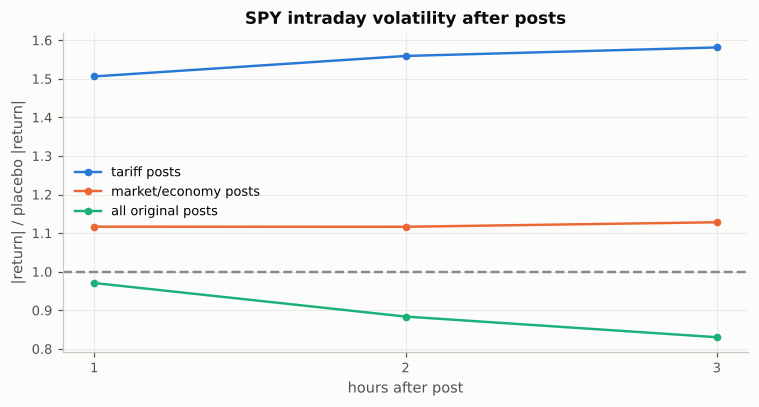

In [24]:
groups = {"tariff posts": orig[orig.topic_tariffs_trade], "market/economy posts": orig[orig.topic_markets_economy],
          "all original posts": orig}
intr = []
for gname, g in groups.items():
    ev_t = MK.decluster(g.t_et, gap="3h")
    if len(ev_t) < 10: print(f"skipping {gname}: too few events"); continue
    for tk in ["SPY", "QQQ", "^VIX"]:
        if tk not in pxh: continue
        out = MK.intraday_event_study(pxh[tk], ev_t, horizons=(1, 2, 3), n_placebo=max(200, N_PLACEBO // 5))
        out.insert(0, "asset", tk); out.insert(0, "posts", gname); intr.append(out)
intr = pd.concat(intr, ignore_index=True)
intr["p_abs_FDR"], intr["sig_abs"] = MK.bh_fdr(intr.p_abs)
display(intr.round(3))
sub = intr[(intr.asset == "SPY")]
fig, ax = plt.subplots(figsize=(7, 3.8))
for i, (gname, g) in enumerate(sub.groupby("posts", sort=False)):
    ax.plot(g.h, g.abs_ratio, "o-", color=C[i], label=gname)
ax.axhline(1, color=PL.GREY, ls="--"); ax.set_xlabel("hours after post"); ax.set_ylabel("|return| / placebo |return|")
ax.set_xticks([1, 2, 3]); ax.legend(); ax.set_title("SPY intraday volatility after posts"); save(fig, "D1_intraday");
tariff_days = D.trading_day_of(orig[orig.topic_tariffs_trade].t_et, rets.index).dropna().unique()
dly = MK.event_study_daily(rets, tariff_days, "SPY", market=None, window=(-1, 1), car_window=(0, 0), n_placebo=N_PLACEBO)
t1 = intr[(intr.posts == "tariff posts") & (intr.asset == "SPY") & (intr.h == 1)].iloc[0]
print(f"\nSPY after tariff posts: hourly |return| x{t1.abs_ratio:.2f} (p={t1.p_abs:.3f}); "
      f"daily |abnormal return| on tariff-post days x{dly['absAR_ratio']:.2f} (p={dly['p_abs']:.3f}, n={dly['n_events']} days)")
SUMMARY.update(intraday_SPY_abs_ratio_1h=t1.abs_ratio, intraday_SPY_p_1h=t1.p_abs,
               daily_SPY_absAR_ratio_tariff_days=dly["absAR_ratio"], daily_SPY_p=dly["p_abs"])

### D2. Case studies (hourly)
These are well-known episodes. The cell prints the actual posts in each window, so you can check the narrative against the data before writing it up. The hourly window only reaches back about 730 days from the download date.


[2025-04-09] relevant posts closest to the case date:
  Tue 08 Apr 09:08  I just had a great call with the Acting President of South Korea. We talked about their tremendous and unsustainable Surplus, Tariffs, Shipbuilding, large scale
  Wed 09 Apr 07:44  This is a GREAT time to move your COMPANY into the United States of America, like Apple, and so many others, in record numbers, are doing. ZERO TARIFFS, and alm
  Wed 09 Apr 09:25  “Fixing Trade and Tariffs is a good thing!” Jamie Dimon, JPMorgan Chase, Chairman & CEO, on Maria B Show!
  Wed 09 Apr 09:37  THIS IS A GREAT TIME TO BUY!!! DJT
  Wed 09 Apr 12:16  Jon Husted is doing an incredible job as Senator for the Great State of Ohio! He served as your Lieutenant Governor for seven years prior to becoming a very dis
  Wed 09 Apr 13:18  Based on the lack of respect that China has shown to the World’s Markets, I am hereby raising the Tariff charged to China by the United States of America to 125
  Thu 10 Apr 09:38  Just out: “INFLATION


[2025-10-10] relevant posts closest to the case date:
  Wed 08 Oct 10:52  Florida Attorney General James Uthmeier is doing a GREAT job for the Sunshine State, which I won BIG in 2016, 2020, and 2024. James is an America First Warrior,
  Wed 08 Oct 10:57  Congressman Chris Smith is a fantastic Representative for the wonderful people of New Jersey's 4th Congressional District! As a Senior Member of the House Commi
  Wed 08 Oct 11:19  Congressman Jeff Van Drew is a "MAGA" Warrior for the incredible people of New Jersey's 2nd Congressional District! As the Chairman of the House Judiciary Subco
  Thu 09 Oct 12:01  Tariffs are only good if you want your Country to be Rich, Influential, and Powerful. If you want your Country to be a Third World Country, you should Vote agai
  Fri 10 Oct 10:57  Some very strange things are happening in China! They are becoming very hostile, and sending letters to Countries throughout the World, that they want to impose
  Fri 10 Oct 16:50  It has just been lea


[2025-03-02] relevant posts closest to the case date:
  Fri 28 Feb 19:02  The Department of Justice has just returned the boxes that Deranged Jack Smith made such a big deal about. They are being brought down to Florida and will somed
  Sat 01 Mar 10:42  The New York Times: "During the Biden administration, Mr. Doocy said, he spent a lot of time 'figuring out how to boil a question down into something that’s eig
  Sun 02 Mar 10:24  A U.S. Crypto Reserve will elevate this critical industry after years of corrupt attacks by the Biden Administration, which is why my Executive Order on Digital
  Mon 03 Mar 13:32  To the Great Farmers of the United States: Get ready to start making a lot of agricultural product to be sold INSIDE of the United States. Tariffs will go on ex


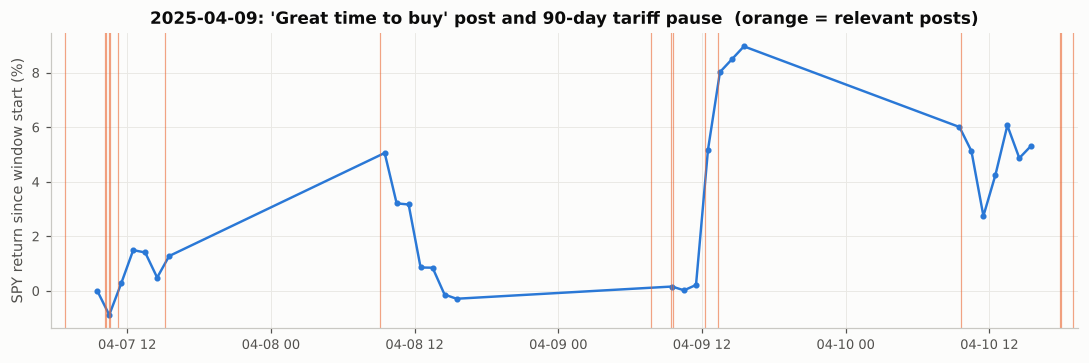

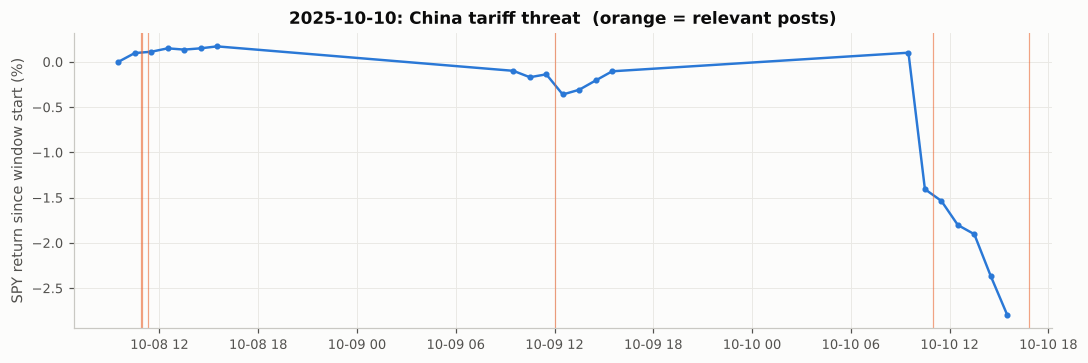

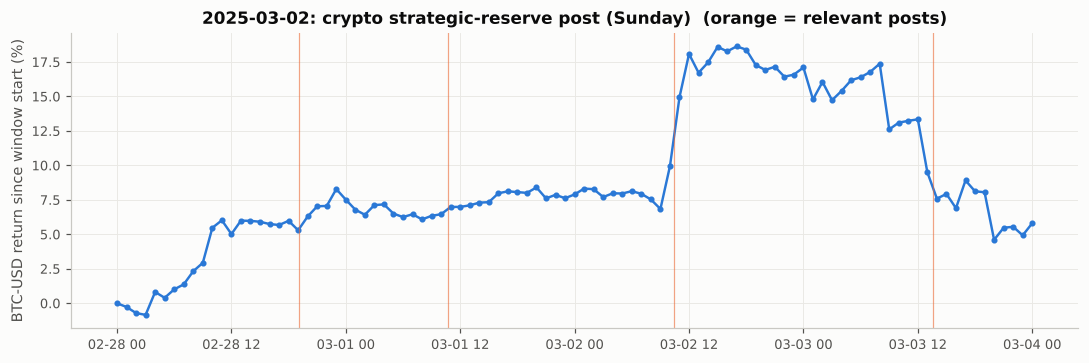

In [25]:
CASES = [("2025-04-09", "SPY", "'Great time to buy' post and 90-day tariff pause"),
         ("2025-10-10", "SPY", "China tariff threat"),
         ("2025-03-02", "BTC-USD", "crypto strategic-reserve post (Sunday)")]
for date, tk, title in CASES:
    t0 = pd.Timestamp(date, tz=D.ET); w0, w1 = t0 - pd.Timedelta("2D"), t0 + pd.Timedelta("2D")
    s_ = pxh[tk].dropna(); s_ = s_[(s_.index >= w0) & (s_.index <= w1)]
    if len(s_) < 5: print(f"[{date}] no hourly data for {tk} in window (outside Yahoo's 730-day range?)"); continue
    pw = orig[(orig.t_et >= w0) & (orig.t_et <= w1) & (orig.topic_tariffs_trade | orig.topic_markets_economy | orig.topic_crypto)]
    fig, ax = plt.subplots(figsize=(10, 3.4))
    ax.plot(s_.index, 100 * (s_ / s_.iloc[0] - 1), color=C[0], marker="o", ms=3)
    for t in pw.t_et: ax.axvline(t, color=C[1], lw=0.8, alpha=0.6)
    ax.set_ylabel(f"{tk} return since window start (%)"); ax.set_title(f"{date}: {title}  (orange = relevant posts)")
    save(fig, f"D2_case_{date}")
    pw = pw.assign(dist=(pw.t_et - (t0 + pd.Timedelta("12h"))).abs()).sort_values("dist").head(8).sort_values("t_et")
    print(f"\n[{date}] relevant posts closest to the case date:")
    for t, txt in zip(pw.t_et, pw.text_nourl): print(f"  {t:%a %d %b %H:%M}  {txt[:160]}")

#### Findings D: tariff posts are short-lived volatility shocks
* **Tariff posts during trading hours** raise the S&P 500's absolute move **1.51× in the next hour**, 1.56× over 2 hours and 1.58× over 3 hours, against time-of-day-matched placebos (all FDR-significant). The Nasdaq rises 1.32–1.37× and the VIX 1.46× at 3 hours. The **direction is not predictable** (mean-return p > 0.4): posts inject *uncertainty*, not a consistent signal.
* **Only tariff posts matter.** All other original posts give 0.97× (not significant), and market or economy posts give 1.12× (not significant after FDR).
* **The effect is gone by the close.** On days with tariff posts, the daily absolute abnormal S&P return is ×0.89 (p = 0.97, 244 days). The market absorbs the shock within hours, as expected in an efficient, highly connected market.
* The **9 April 2025** case shows it directly: "THIS IS A GREAT TIME TO BUY!!! DJT" at 09:37, followed by the 90-day tariff pause post at 13:18 and one of the largest one-day rallies on record.

## Part E. Geopolitics: how he talks about countries
* **E1:** stance dynamics towards countries and their leaders, including friend/foe switches and regime shifts.
* **E2:** a **multiplex** network with *conflict*, *trade* and *diplomacy* layers: is his geopolitics compartmentalised, or are the issues fused?

In [26]:
from matplotlib.colors import LinearSegmentedColormap
DIV_CMAP = LinearSegmentedColormap.from_list("stance", [PL.DIVERGING[2], PL.DIVERGING[1], PL.DIVERGING[0]])  # red=hostile, blue=friendly
DIV_CMAP.set_bad("#fcfcfb")
cm = GEO.country_mentions(own)   # own voice only (quotations excluded)
print(f"{len(cm):,} (post, country) mentions across {cm.country.nunique()} countries")
print("frame shares among country mentions:", {f: round(cm[f'frame_{f}'].mean(), 3) for f in GEO.LAYERS})
cm.groupby("country").agg(mentions=("stance", "size"), mean_stance=("stance", "mean"),
                          share_hostile=("stance", lambda s: (s < -0.2).mean())).sort_values("mentions", ascending=False).head(20).round(3)

2,436 (post, country) mentions across 36 countries
frame shares among country mentions: {'conflict': np.float64(0.459), 'trade': np.float64(0.255), 'diplomacy': np.float64(0.305)}


,mentions,mean_stance,share_hostile
country,,,
Iran,447,-0.028,0.365
China,354,0.028,0.314
Russia,340,-0.230,0.535
Ukraine,191,-0.134,0.482
Israel,168,-0.005,0.387
Canada,97,0.137,0.206
Venezuela,89,0.058,0.292
Afghanistan,81,-0.313,0.679
Mexico,77,0.141,0.260


### E1. Stance towards countries over time: friends, foes and regime shifts
Stance is the mean sentence-level sentiment towards the country *or its leader* (e.g. China + Xi), averaged by month. Months with fewer than 3 mentions are blank. **Regime shifts** are found by binary segmentation: the best mean-shift split is accepted only if it beats a **permutation null**. A sign flip between regimes means a friend → foe (or foe → friend) switch. This is a discrete, tipping-point-like change in a relationship.

,months,mean_stance,n_changepoints,changepoints,regime_means,sign_flips
country,,,,,,
Iran,19,-0.1129,1,2025-03,-0.34 → -0.03,0
Russia,47,-0.2471,1,2024-11,-0.38 → -0.08,0
Ukraine,34,-0.1659,1,2026-07,-0.20 → +0.15,1
China,47,0.0266,0,,+0.03,0
Israel,21,-0.0567,0,,-0.06,0
Canada,11,0.1573,0,,+0.16,0
Venezuela,12,0.0382,0,,+0.04,0
Afghanistan,10,-0.4828,0,,-0.48,0
Mexico,8,-0.0060,0,,-0.01,0


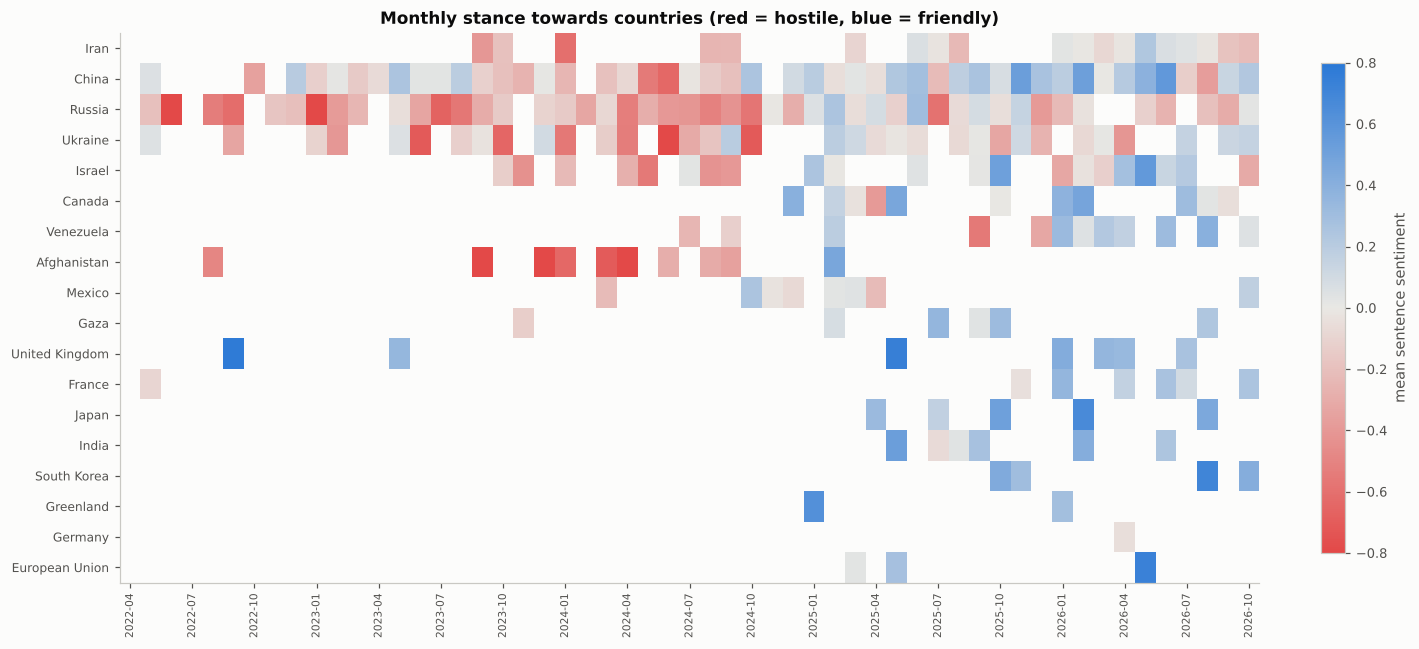

In [27]:
st_panel, st_n = GEO.stance_panel(cm, freq="MS", min_mentions=3, top=18)
fig, ax = plt.subplots(figsize=(13, 6))
im = ax.imshow(np.ma.masked_invalid(st_panel.T.values), aspect="auto", cmap=DIV_CMAP, vmin=-0.8, vmax=0.8)
ax.set_yticks(range(st_panel.shape[1]), st_panel.columns, fontsize=8)
xt = list(range(0, len(st_panel), 3)); ax.set_xticks(xt, [f"{st_panel.index[i]:%Y-%m}" for i in xt], rotation=90, fontsize=7)
ax.grid(False); ax.set_title("Monthly stance towards countries (red = hostile, blue = friendly)")
plt.colorbar(im, ax=ax, fraction=0.02, label="mean sentence sentiment")
save(fig, "E1_stance_heatmap")
regimes = GEO.stance_regimes(st_panel, min_months=8, n_perm=200 if FAST else 1000)
display(regimes.sort_values("n_changepoints", ascending=False))
SUMMARY.update(countries_with_regime_shift=int((regimes.n_changepoints > 0).sum()),
               countries_with_sign_flip=int((regimes.sign_flips > 0).sum()))

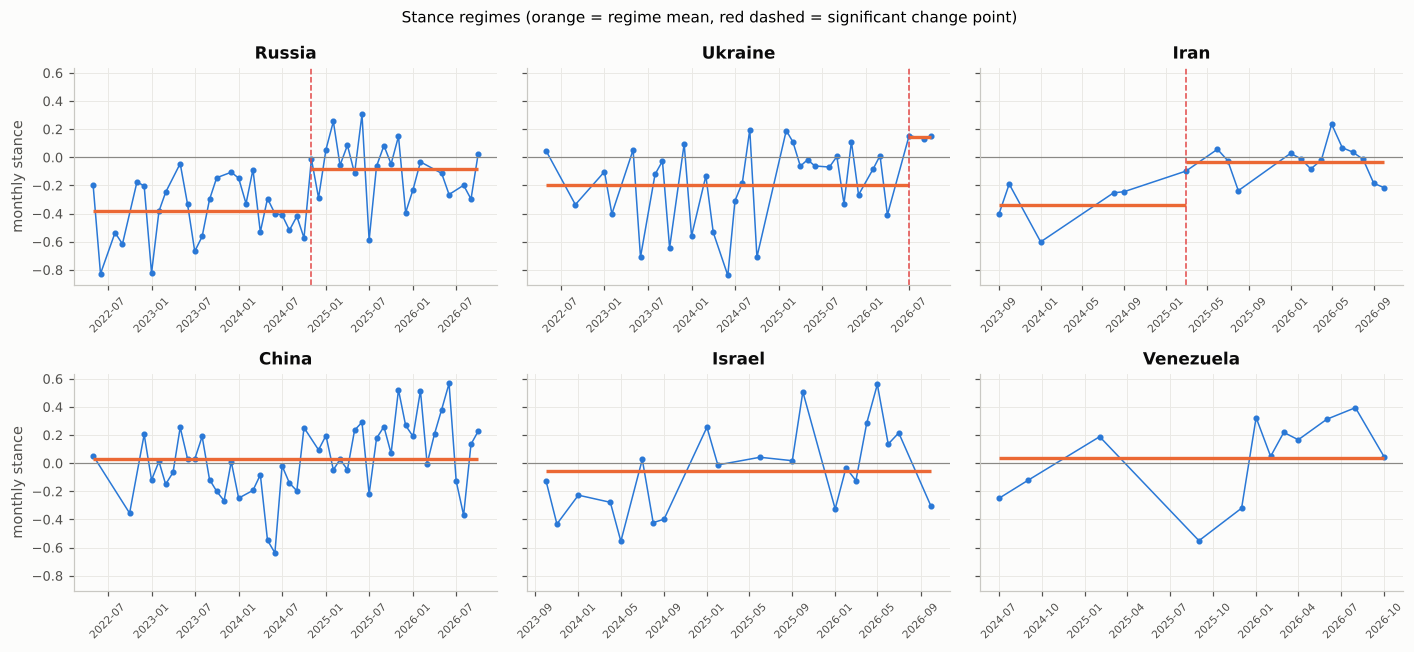

In [28]:
show = [c for c in regimes.sort_values(["n_changepoints", "months"], ascending=False).index[:6]]
fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharey=True)
for a, c in zip(axes.ravel(), show):
    s = st_panel[c].dropna()
    a.plot(s.index, s.values, "o-", ms=3, lw=1, color=C[0])
    cps = [pd.Timestamp(x.strip() + "-01") for x in regimes.loc[c, "changepoints"].split(",") if x.strip()]
    bounds = [s.index[0]] + cps + [s.index[-1] + pd.Timedelta("1D")]
    for lo, hi in zip(bounds[:-1], bounds[1:]):
        m = s[(s.index >= lo) & (s.index < hi)].mean()
        a.hlines(m, lo, hi - pd.Timedelta("1D"), color=C[1], lw=2.2)
    for d in cps: a.axvline(d, color=C[7], ls="--", lw=1)
    a.axhline(0, color=PL.GREY, lw=0.8); a.set_title(c); a.tick_params(axis="x", labelrotation=45, labelsize=7)
axes[0, 0].set_ylabel("monthly stance"); axes[1, 0].set_ylabel("monthly stance")
fig.suptitle("Stance regimes (orange = regime mean, red dashed = significant change point)", fontsize=10)
save(fig, "E1_stance_regimes");

**Did the stance change when he took office?** We split all country mentions at the inauguration (20 Jan 2025) and compare the stance distributions with a Mann–Whitney test, the hostile share, and the share of each frame.

In [29]:
INAUG = pd.Timestamp("2025-01-20")
cm["period"] = np.where(cm.date >= INAUG, "in office", "before")
off = cm.groupby("period").agg(mentions=("stance", "size"), mean_stance=("stance", "mean"),
                               hostile_share=("stance", lambda s: (s < -0.2).mean()),
                               conflict_frame=("frame_conflict", "mean"), trade_frame=("frame_trade", "mean"),
                               diplomacy_frame=("frame_diplomacy", "mean")).loc[["before", "in office"]]
mw_off = stats.mannwhitneyu(cm[cm.period == "before"].stance, cm[cm.period == "in office"].stance)
display(off.round(3)); print(f"Mann-Whitney p = {mw_off.pvalue:.2g}")
topc = cm.country.value_counts().index[:12]
byc = cm[cm.country.isin(topc)].groupby(["country", "period"]).stance.mean().unstack()[["before", "in office"]]
byc["change"] = byc["in office"] - byc["before"]
display(byc.sort_values("change").round(2))
SUMMARY.update(stance_before=off.loc["before", "mean_stance"], stance_in_office=off.loc["in office", "mean_stance"], stance_shift_p=mw_off.pvalue)

,mentions,mean_stance,hostile_share,conflict_frame,trade_frame,diplomacy_frame
period,,,,,,
before,882,-0.141,0.48,0.367,0.120,0.156
in office,1554,0.110,0.28,0.512,0.331,0.389


Mann-Whitney p = 6.7e-30


period,before,in office,change
country,,,
Mexico,0.22,0.04,-0.17
Canada,0.27,0.11,-0.16
United Kingdom,0.35,0.44,0.08
France,-0.05,0.13,0.18
Venezuela,-0.12,0.11,0.23
China,-0.08,0.15,0.23
Israel,-0.15,0.11,0.26
Iran,-0.28,-0.00,0.27
Ukraine,-0.27,0.01,0.28


### E2. Multiplex geopolitical network: war, trade and diplomacy layers
Each layer links two countries when he mentions both in a post with that frame. For each country, $k_i^\alpha$ counts its mentions in layer $\alpha$. The **multiplex participation coefficient** $P_i=\frac{M}{M-1}\big[1-\sum_\alpha (k_i^\alpha/o_i)^2\big]$ is 0 if a country appears in only one kind of discourse, such as only trade. It is 1 if the country is spread evenly across war, trade and diplomacy. **Edge overlap** and **inter-layer correlation** measure how strongly the layers are coupled.

In [30]:
ML, ML_s = GEO.multiplex(cm, min_mentions=10)
P = GEO.participation_coefficient(ML_s)
mst_ = GEO.multiplex_stats(ML)
print("edges per layer:", mst_["edges_per_layer"], "| global edge overlap:", round(mst_["global_edge_overlap"], 3))
print("layer Jaccard:", {k: round(v, 3) for k, v in mst_["layer_jaccard"].items()})
print("inter-layer Spearman correlation of country strengths:\n", ML_s.corr(method="spearman").round(2).to_string())
mp = ML_s.assign(total=ML_s.sum(axis=1), P=P, dominant=ML_s.idxmax(axis=1)).sort_values("total", ascending=False)
display(mp.head(20).round(3))
SUMMARY.update(multiplex_edge_overlap=mst_["global_edge_overlap"], mean_participation_P=float(P.mean()),
               share_countries_P_above_0_8=float((P > 0.8).mean()))

edges per layer: {'conflict': 169, 'trade': 114, 'diplomacy': 168} | global edge overlap: 0.779
layer Jaccard: {'conflict~trade': 0.636, 'conflict~diplomacy': 0.764, 'trade~diplomacy': 0.602}
inter-layer Spearman correlation of country strengths:
            conflict  trade  diplomacy
conflict       1.00   0.76       0.85
trade          0.76   1.00       0.81
diplomacy      0.85   0.81       1.00


,conflict,trade,diplomacy,total,P,dominant
country,,,,,,
Iran,284,101.0,142,527.0,0.900,conflict
Russia,146,53.0,83,282.0,0.915,conflict
China,87,100.0,76,263.0,0.994,trade
Ukraine,119,31.0,68,218.0,0.877,conflict
Israel,101,22.0,60,183.0,0.860,conflict
Canada,22,55.0,32,109.0,0.928,trade
Venezuela,37,36.0,26,99.0,0.989,conflict
Gaza,49,6.0,31,86.0,0.811,conflict
Mexico,28,23.0,18,69.0,0.984,conflict


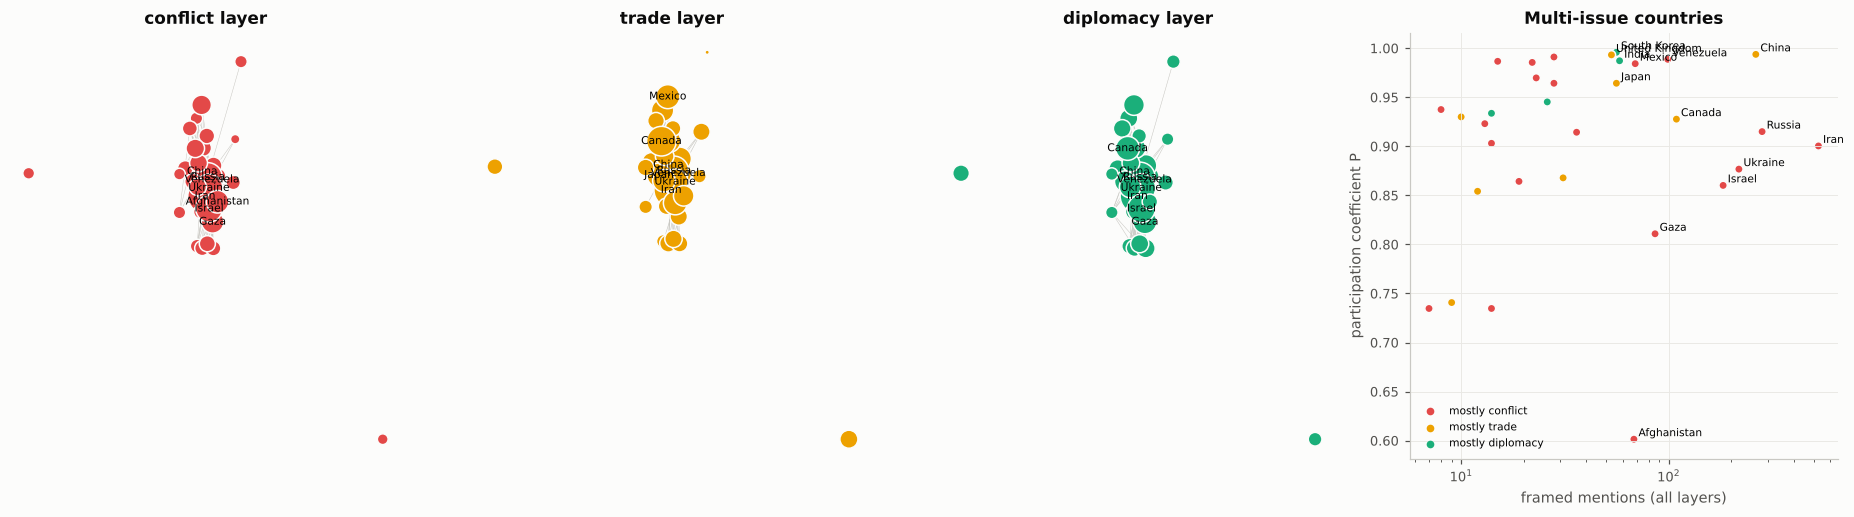

In [31]:
agg = nx.Graph()
for L, g in ML.items():
    for u, v, d in g.edges(data=True):
        agg.add_edge(u, v, weight=agg[u][v]["weight"] + d["weight"] if agg.has_edge(u, v) else d["weight"])
agg.add_nodes_from(ML_s.index)
pos = nx.spring_layout(agg, weight="weight", seed=4, k=1.8 / np.sqrt(max(1, agg.number_of_nodes())))
fig, axes = plt.subplots(1, 4, figsize=(17, 4.8), gridspec_kw=dict(width_ratios=[1, 1, 1, 1.1]))
for a, (L, col) in zip(axes[:3], zip(GEO.LAYERS, [C[7], C[3], C[2]])):
    g = ML[L]; a.axis("off")
    w = np.array([d["weight"] for *_, d in g.edges(data=True)]) if g.number_of_edges() else np.array([1])
    nx.draw_networkx_edges(g, pos, width=0.3 + 2.5 * w / w.max(), edge_color="#c9c8c3", ax=a)
    kmax = max(1.0, ML_s[L].max())
    nx.draw_networkx_nodes(g, pos, node_size=[8 + 500 * np.sqrt(ML_s.loc[n, L] / kmax) for n in g], node_color=col, edgecolors="#fcfcfb", ax=a)
    top_ = ML_s[L].sort_values(ascending=False).index[:8]
    nx.draw_networkx_labels(g, pos, labels={n: n for n in top_}, font_size=7, ax=a)
    a.set_title(f"{L} layer")
a = axes[3]
dom_col = {"conflict": C[7], "trade": C[3], "diplomacy": C[2]}
a.scatter(mp.total, mp.P, s=30, c=[dom_col[d] for d in mp.dominant], edgecolors="#fcfcfb")
for c in mp.index[:14]: a.annotate(c, (mp.total[c], mp.P[c]), fontsize=7, xytext=(3, 2), textcoords="offset points")
a.set_xscale("log"); a.set_xlabel("framed mentions (all layers)"); a.set_ylabel("participation coefficient P")
for k, v in dom_col.items(): a.scatter([], [], color=v, label=f"mostly {k}")
a.legend(fontsize=7); a.set_title("Multi-issue countries")
save(fig, "E2_multiplex");

#### Findings E: a regime shift at the inauguration, and fused issues
* **Office effect.** Across 2,436 own-voice mentions of 36 countries, his mean stance moved from **−0.14 before the inauguration to +0.11 in office** (Mann–Whitney p ≈ 7×10⁻³⁰). The hostile share fell from 48% to 28%. At the same time, trade framing (12% → 33%) and diplomacy framing (16% → 39%) both roughly tripled. The *rules of interaction* changed when his role changed: an opposition candidate attacking foreign policy became a head of state doing deals.
* **Exceptions.** Stance towards **Canada** (+0.27 → +0.11) and **Mexico** (+0.22 → +0.04) *worsened*, matching the 2025 tariff conflicts with the two closest trading partners.
* **Change points** detected by permutation tests: Russia in Nov 2024 (−0.38 → −0.08), Iran in Mar 2025 (−0.34 → −0.03), and Ukraine in Jul 2026 (−0.20 → +0.15, a sign flip).
* **A multiplex without compartments.** The conflict, trade and diplomacy layers share most of their ties: global edge overlap is 0.78, pairwise Jaccard 0.60–0.76, and country activity correlates across layers at ρ = 0.76–0.85. The mean participation coefficient is **P = 0.91**, and 88% of countries have P > 0.8. He talks about almost every country in all three registers at once. War, trade and deals are one fused, multiplex game rather than separate policy domains.

## Part F. Public attention: politics, geopolitics, and beyond (culture, brands, sport, health, places)
Financial markets turned out to react only briefly (Part D). What about people's *attention*? Wikipedia pageviews are a daily, global and free measure of what people look up. The **Donald Trump** article in 24 language editions measures foreign publics, and English articles measure issues and cultural targets.

**Event design used throughout.** An event is a day with an original post that mentions the target, with events at least 5 days apart. The response is the change in log daily views from the 10 days before to days 0–2. It is compared with the **same statistic on placebo days of the same article**, so each article's own volatility and weekly cycle form its null. The **pre-trend** (days −3..−1 vs −10..−4) shows whether attention was *already* rising. Article-level $p$-values are FDR-corrected.

### F1. Foreign publics
The daily views of the *Donald Trump* article in 24 language editions measure each language community's attention. The panel is **cross-sectionally demeaned**, which removes worldwide Trump news. A post about country C should then raise attention in C's language *relative to all other languages*. Editions with no target country (Italian, Dutch, Swedish, Indonesian, Finnish, Czech) act as controls.

pooled across languages: {'n_events': 1188.0, 'mean_response_sd': 0.1423, 'placebo_mean': -0.0335, 'placebo_sd': 0.0243, 'z': 7.2287, 'p': 0.0017}


,n_events,mean_response_sd,placebo_mean,p,p_FDR,sig_FDR
unit,,,,,,
hu,11,1.113,-0.051,0.000,0.001,True
pl,11,0.910,-0.022,0.002,0.005,True
pt,16,0.860,-0.034,0.000,0.001,True
ja,32,0.747,-0.050,0.000,0.001,True
da,17,0.736,-0.022,0.000,0.001,True
tr,15,0.636,-0.023,0.012,0.024,True
vi,14,0.571,-0.038,0.014,0.025,True
hi,31,0.431,-0.020,0.002,0.005,True
he,101,0.288,-0.057,0.000,0.001,True


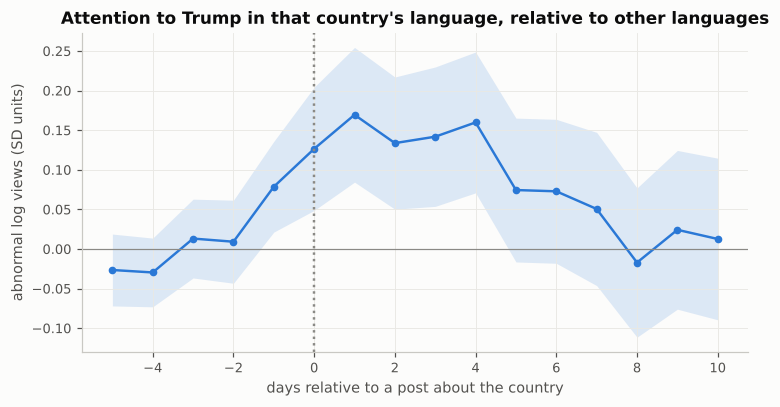

In [32]:
# F1: foreign publics - does a post about country C raise attention to Trump in C's language, relative to other languages?
ev = {lg: GEO.decluster_days(cm[cm.country.isin(cs)].date, gap=3) for lg, cs in EXT.LANG_COUNTRIES.items() if cs and lg in fa}
wa = GEO.panel_event_study(fa, ev, window=(-5, 10), resp=(0, 2), log=True, n_placebo=N_PLACEBO)
print("pooled across languages:", {k: round(float(v), 4) for k, v in wa["pooled"].items()})
wa["table"]["p_FDR"], wa["table"]["sig_FDR"] = MK.bh_fdr(wa["table"].p)
display(wa["table"].round(3).sort_values("mean_response_sd", ascending=False))
fa_p = wa["path"]
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(fa_p.offset, fa_p["mean"], "o-", color=C[0]); ax.fill_between(fa_p.offset, fa_p["mean"] - 1.96 * fa_p.se, fa_p["mean"] + 1.96 * fa_p.se, color=C[0], alpha=0.15, lw=0)
ax.axvline(0, color=PL.GREY, ls=":"); ax.axhline(0, color=PL.GREY, lw=0.8)
ax.set_xlabel("days relative to a post about the country"); ax.set_ylabel("abnormal log views (SD units)")
ax.set_title("Attention to Trump in that country's language, relative to other languages"); save(fig, "F1_foreign_publics")
SUMMARY.update(foreign_attention_z=wa["pooled"].get("z"), foreign_attention_effect_sd=wa["pooled"].get("mean_response_sd"),
               foreign_languages_sig=int(wa["table"].sig_FDR.sum()), foreign_languages_tested=len(wa["table"]))

### F2–F3. Issues and culture: which targets' attention responds?
There are 40 English-Wikipedia targets in six domains:
* policy and geopolitics (16 issue articles);
* brands;
* sport;
* entertainment;
* health and science;
* places and heritage.

The **whole target list is tested and reported**, including the non-significant ones, so the results are not cherry-picked. The right-hand panel separates spikes that arrive **suddenly** (no build-up in the 3 days before) from spikes that **ride a surge already under way**.

In [33]:
# F2 + F3: issues (policy, geopolitics) and culture (brands, sport, entertainment, health & science, places & heritage)
targets = {art: ("policy & geopolitics", trig, kind) for art, (kind, trig) in EXT.ISSUE_ARTICLES.items()}
targets.update({art: (dom, rx, cs) for art, (dom, rx, cs) in CU.CULTURE.items()})
views = pd.concat([ia, cv], axis=1)
att_rows, att_ev = [], []
for art, (dom, a1, a2) in targets.items():
    if art not in views or views[art].dropna().empty: continue
    if dom == "policy & geopolitics":
        mask = orig[f"topic_{a1}"] if a2 == "topic" else orig.entities.map(lambda es: any(t in es for t in a1))
        days = CU.decluster(orig.loc[mask, "t_et"].dt.tz_localize(None).dt.normalize(), gap=5)
    else:
        days = CU.mention_days(orig, a1, a2, gap=5)
    ev_, sm = CU.event_responses(views[art].dropna(), days, n_placebo=N_PLACEBO)
    if not sm: continue
    att_rows.append(dict(article=art, domain=dom, **sm)); att_ev.append(ev_.assign(article=art, domain=dom))
att = pd.DataFrame(att_rows).set_index("article"); att_ev = pd.concat(att_ev, ignore_index=True)
att["p_FDR"], att["sig_FDR"] = MK.bh_fdr(att.p)
cols = ["domain", "n_events", "pct_change", "median_pct", "max_pct", "mean_z", "pre_trend", "p", "p_FDR", "sig_FDR"]
display(att[cols].sort_values(["domain", "mean_z"], ascending=[True, False]).round(3))
dom_tab = att_ev.groupby("domain").agg(events=("z", "size"), mean_z=("z", "mean"), share_z_above_2=("z", lambda z: (z > 2).mean()),
                                       median_pct=("delta", lambda d: 100 * (np.exp(d.median()) - 1)))
dom_tab["stouffer_Z"] = att_ev.groupby("domain").z.sum() / np.sqrt(dom_tab.events)
dom_tab["articles_sig_FDR"] = att.groupby("domain").sig_FDR.sum()
display(dom_tab.round(3).sort_values("mean_z", ascending=False))
print(f"Share of all {len(att_ev)} events with z > 2: {(att_ev.z > 2).mean():.1%} (about 2.3% expected by chance)")
SUMMARY.update(attention_articles_sig=int(att.sig_FDR.sum()), attention_articles_tested=len(att),
               attention_events=len(att_ev), attention_share_z_gt2=float((att_ev.z > 2).mean()))

,domain,n_events,pct_change,median_pct,max_pct,mean_z,pre_trend,p,p_FDR,sig_FDR
article,,,,,,,,,,
Cracker Barrel,brands,1,463.288,463.288,463.288,8.249,2.369,0.001,0.003,True
Coca-Cola,brands,1,43.867,43.867,43.867,2.460,-0.001,0.035,0.052,False
Jaguar Cars,brands,1,62.757,62.757,62.757,2.273,0.438,0.024,0.038,True
American Eagle Outfitters,brands,1,63.984,63.984,63.984,2.058,0.654,0.039,0.054,False
"Tesla, Inc.",brands,2,30.806,30.806,58.439,1.481,0.077,0.055,0.069,False
TikTok,brands,14,21.764,9.585,580.207,1.322,0.108,0.000,0.001,True
Intel,brands,10,10.515,7.083,61.621,0.638,0.043,0.045,0.058,False
Apple Inc.,brands,22,0.954,-2.947,70.367,0.099,0.028,0.650,0.667,False
Kennedy Center,entertainment,21,91.021,39.466,2101.803,2.474,0.316,0.000,0.001,True


,events,mean_z,share_z_above_2,median_pct,stouffer_Z,articles_sig_FDR
domain,,,,,,
entertainment,44,2.255,0.386,38.041,14.960,4
brands,52,0.867,0.173,6.015,6.249,3
places & heritage,19,0.711,0.158,3.323,3.099,1
policy & geopolitics,953,0.490,0.116,0.828,15.118,14
sport,89,0.430,0.124,1.794,4.055,3
health & science,15,0.215,0.067,0.700,0.832,1


Share of all 1172 events with z > 2: 13.0% (about 2.3% expected by chance)


Significant spikes (z > 2): 82 with no build-up before the post ('sudden'), 70 joining a surge already under way ('surge-riding')
Sudden examples: Gaza_Strip (2023-10-07, +48069%), Venezuela (2026-01-03, +8890%), Jimmy Kimmel (2025-09-17, +6270%), Iran (2026-02-28, +3199%), Columbus Day (2025-04-27, +1803%), LIV Golf (2023-06-06, +1221%)
Surge-riding examples: Kennedy Center (2026-09-15, +2102%), Kennedy Center (2026-05-29, +2045%), Jeffrey_Epstein (2026-02-02, +1766%), U.S._Immigration_and_Customs_Enforcement (2025-06-08, +750%), Jimmy Kimmel (2024-03-10, +686%), Iran (2025-06-17, +653%)


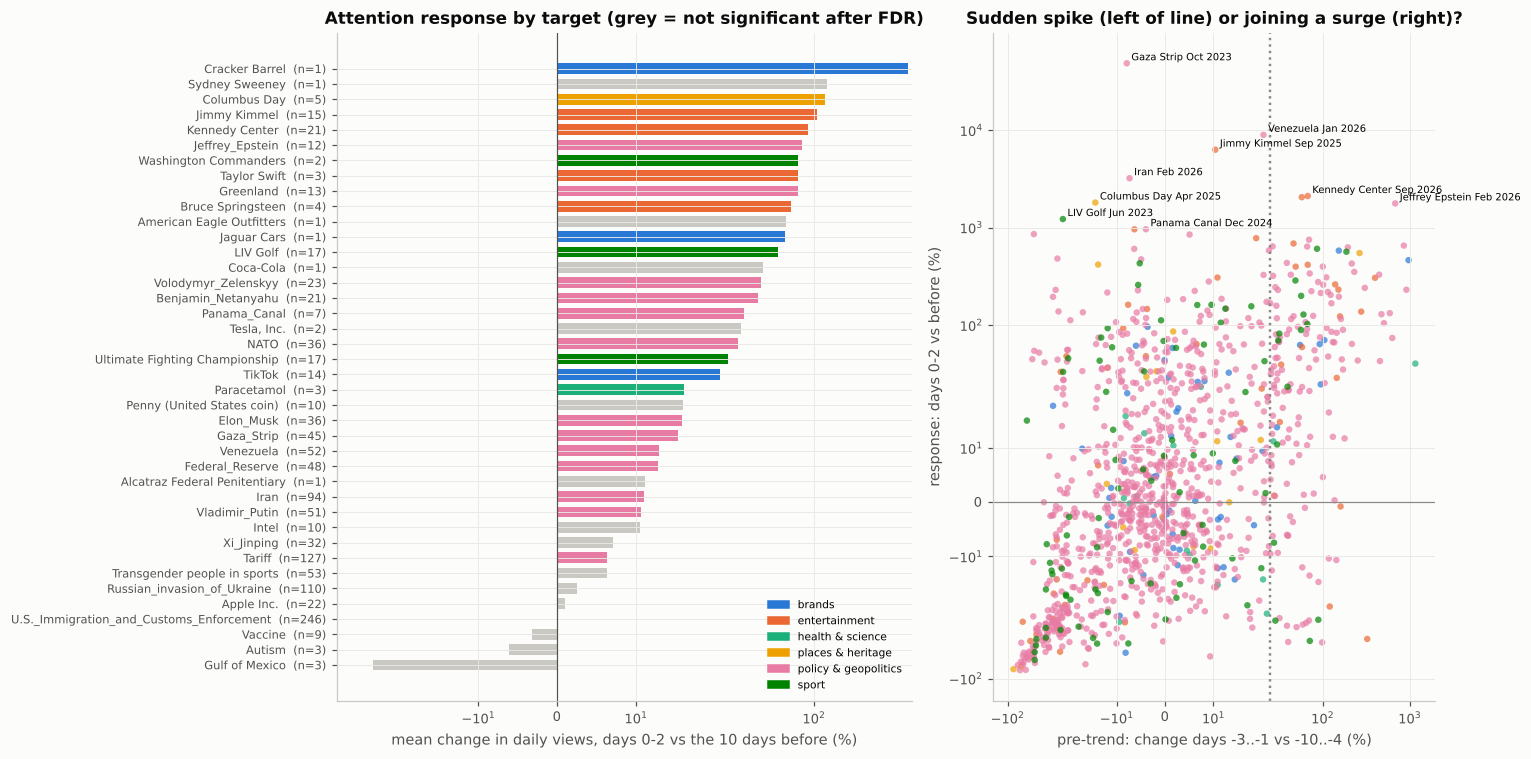

In [34]:
order = att.sort_values("pct_change").index
dom_col = dict(zip(sorted(att.domain.unique()), C))
fig, ax = plt.subplots(1, 2, figsize=(14, 7), gridspec_kw=dict(width_ratios=[1.3, 1]))
ax[0].barh(range(len(order)), att.loc[order, "pct_change"], color=[dom_col[d] if s else "#c9c8c3" for d, s in zip(att.loc[order, "domain"], att.loc[order, "sig_FDR"])], height=0.7)
ax[0].set_yticks(range(len(order)), [f"{a}  (n={att.loc[a, 'n_events']})" for a in order], fontsize=7.5)
ax[0].axvline(0, color=PL.INK2, lw=0.8); ax[0].set_xscale("symlog", linthresh=20)
ax[0].set_xlabel("mean change in daily views, days 0-2 vs the 10 days before (%)")
ax[0].set_title("Attention response by target (grey = not significant after FDR)")
from matplotlib.patches import Patch
ax[0].legend(handles=[Patch(color=c, label=d) for d, c in dom_col.items()], fontsize=7, loc="lower right")
# initiator vs amplifier: was attention already rising before he posted?
for d, g in att_ev.groupby("domain"):
    ax[1].scatter(100 * (np.exp(g.pre_delta) - 1), 100 * (np.exp(g.delta) - 1), s=18, color=dom_col[d], alpha=0.7, edgecolors="none", label=d)
big = att_ev.sort_values("delta", ascending=False).drop_duplicates("article").head(9)
for _, r in big.iterrows():
    ax[1].annotate(f"{r.article.replace('_', ' ')} {r.day:%b %Y}", (100 * (np.exp(r.pre_delta) - 1), 100 * (np.exp(r.delta) - 1)), fontsize=6.5, xytext=(3, 2), textcoords="offset points")
ax[1].set_xscale("symlog", linthresh=20); ax[1].set_yscale("symlog", linthresh=20)
ax[1].axvline(25, color=PL.GREY, ls=":"); ax[1].axhline(0, color=PL.GREY, lw=0.8)
ax[1].set_xlabel("pre-trend: change days -3..-1 vs -10..-4 (%)"); ax[1].set_ylabel("response: days 0-2 vs before (%)")
ax[1].set_title("Sudden spike (left of line) or joining a surge (right)?")
save(fig, "F2_attention_targets")
ini = att_ev[(att_ev.z > 2) & (att_ev.pre_delta < np.log(1.25))]; amp = att_ev[(att_ev.z > 2) & (att_ev.pre_delta >= np.log(1.25))]
print(f"Significant spikes (z > 2): {len(ini)} with no build-up before the post ('sudden'), {len(amp)} joining a surge already under way ('surge-riding')")
print("Sudden examples:", ", ".join(f"{r.article} ({r.day:%Y-%m-%d}, +{100 * (np.exp(r.delta) - 1):.0f}%)" for _, r in ini.sort_values("delta", ascending=False).head(6).iterrows()))
print("Surge-riding examples:", ", ".join(f"{r.article} ({r.day:%Y-%m-%d}, +{100 * (np.exp(r.delta) - 1):.0f}%)" for _, r in amp.sort_values("delta", ascending=False).head(6).iterrows()))
SUMMARY.update(spikes_sudden=len(ini), spikes_surge_riding=len(amp))

### F4. Consumer brands: does the stock move too?
For listed brands, we measure the **market-model abnormal return** over trading days 0–1 after each post, using SPY as the market. It is expressed as a $z$-score against the same stock's 2-day abnormal returns on all other days, and as a percentile rank.

In [35]:
brand_rows = []
for art, tk in CU.BRAND_TICKERS.items():
    if tk not in brets: continue
    dom, rx, cs = CU.CULTURE[art]
    days = CU.mention_days(orig, rx, cs, gap=5)
    tdays = D.trading_day_of(pd.Series(days.tz_localize(D.ET) + pd.Timedelta("9h")), brets.index).dropna().unique()
    z = CU.stock_event_z(brets, tk, tdays)
    brand_rows.append(z.assign(target=art))
brand_rows = [z for z in brand_rows if len(z)]
if not brand_rows:
    print("No brand-mention events with stock data in this sample (e.g. DEMO data) - skipping")
else:
    brand = pd.concat(brand_rows, ignore_index=True).drop_duplicates(["day", "ticker"])
    brand["CAR_%"] = 100 * (np.exp(brand.CAR) - 1)
    bsum = brand.groupby(["ticker"]).agg(events=("z", "size"), mean_CAR_pct=("CAR_%", "mean"), mean_abs_z=("z", lambda z: z.abs().mean()),
                                         max_CAR_pct=("CAR_%", "max"), events_beyond_99pct=("pct_rank", lambda r: ((r > 0.99) | (r < 0.01)).sum()))
    display(bsum.round(2))
    display(brand.sort_values("z", key=abs, ascending=False).head(8)[["day", "ticker", "target", "CAR_%", "z", "pct_rank"]].round(3))
    n_ext = int(((brand.pct_rank > 0.99) | (brand.pct_rank < 0.01)).sum())
    p_ext = stats.binomtest(n_ext, len(brand), 0.02, alternative="greater").pvalue
    print(f"{n_ext} of {len(brand)} brand events fall in the stock's most extreme 2% of 2-day moves (2% expected; binomial p = {p_ext:.2g})")
    SUMMARY.update(brand_events=len(brand), brand_extreme_moves=n_ext, brand_extreme_p=p_ext)

,events,mean_CAR_pct,mean_abs_z,max_CAR_pct,events_beyond_99pct
ticker,,,,,
AAPL,22,0.15,0.95,4.59,0
AEO,1,10.57,2.43,10.57,1
CBRL,1,14.36,3.22,14.36,1
INTC,10,2.40,1.32,15.11,2
KO,1,1.47,1.02,1.47,0
TSLA,2,13.23,2.94,13.86,2


,day,ticker,target,CAR_%,z,pct_rank
32,2026-06-18,INTC,Intel,15.105,3.371,0.992
0,2025-08-26,CBRL,Cracker Barrel,14.357,3.216,0.996
36,2025-03-21,TSLA,"Tesla, Inc.",13.858,3.069,0.994
35,2025-03-11,TSLA,"Tesla, Inc.",12.593,2.805,0.994
19,2026-07-24,AAPL,Apple Inc.,4.592,2.515,0.989
1,2025-08-04,AEO,American Eagle Outfitters,10.573,2.431,0.991
33,2026-08-18,INTC,Intel,-9.669,-2.424,0.010
6,2025-03-12,AAPL,Apple Inc.,-4.177,-2.400,0.017


6 of 37 brand events fall in the stock's most extreme 2% of 2-day moves (2% expected; binomial p = 8.7e-05)


### F5. Attention cascade sizes
How many *extra* views does one post generate? The cascade size is the excess over the pre-event median, summed over days 0–6. In complex social systems, cascade sizes are typically **heavy-tailed**, so a few events carry most of the effect. We fit the tail with the Clauset–Shalizi–Newman method, compare it with a lognormal, and measure concentration.

618 positive cascades; total excess views 46,050,712; top 10% of events = 84% of all excess attention
tail fit: {'alpha': 1.828, 'alpha_se': 0.081, 'xmin': 52708.203, 'n_tail': 105, 'KS': 0.051, 'p_gof': 0.59, 'LR_vs_lognormal': -0.924, 'p_LR_lognormal': 0.356, 'LR_vs_exponential': 3.236, 'p_LR_exponential': 0.001}


,article,day,excess,z,pre_delta
504,Jeffrey_Epstein,2026-02-02,6137653.0,8.96,2.06
147,Gaza_Strip,2023-10-07,5295091.5,23.04,-0.08
426,Venezuela,2026-01-03,2397137.0,25.91,0.19
356,Iran,2026-02-28,2367578.5,15.92,-0.08
339,Iran,2025-06-17,1466117.0,9.21,2.26
1,Greenland,2025-01-06,1319919.5,9.35,0.22
883,Volodymyr_Zelenskyy,2025-02-28,1243898.0,7.01,-0.69
355,Iran,2026-02-23,1204000.5,0.54,0.34


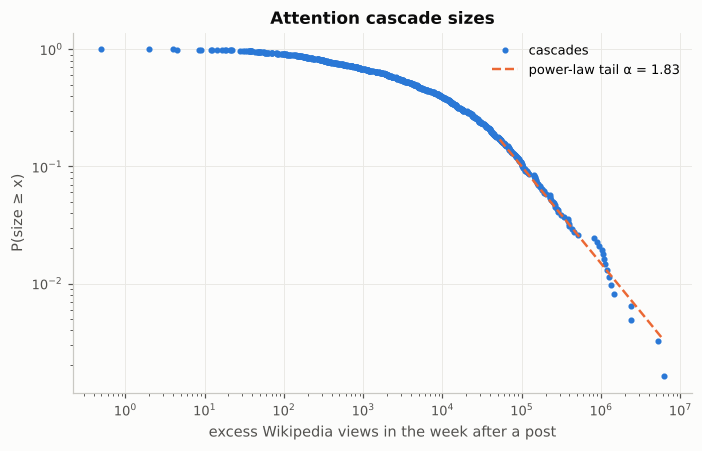

In [36]:
sizes = att_ev.excess[att_ev.excess > 0].to_numpy()
f_c = PP.fit_powerlaw(sizes, min_tail=20); PP.compare_tails(sizes, f_c); PP.powerlaw_pvalue(sizes, f_c, n_boot=max(50, N_BOOT // 2))
srt = np.sort(sizes)[::-1]
top10 = srt[: max(1, len(srt) // 10)].sum() / srt.sum()
print(f"{len(sizes)} positive cascades; total excess views {srt.sum():,.0f}; top 10% of events = {top10:.0%} of all excess attention")
print("tail fit:", {k: (round(v, 3) if isinstance(v, float) else v) for k, v in f_c.summary().items()})
display(att_ev.sort_values("excess", ascending=False).head(8)[["article", "day", "excess", "z", "pre_delta"]].round(2))
fig, ax = plt.subplots(figsize=(6.5, 4.2))
xs, ys = PP.ccdf(sizes); ax.loglog(xs, ys, "o", ms=3, color=C[0], label="cascades")
xx = np.logspace(np.log10(f_c.xmin), np.log10(sizes.max()), 50)
ax.loglog(xx, np.mean(sizes >= f_c.xmin) * (xx / f_c.xmin) ** (1 - f_c.alpha), "--", color=C[1], label=f"power-law tail α = {f_c.alpha:.2f}")
ax.set_xlabel("excess Wikipedia views in the week after a post"); ax.set_ylabel("P(size ≥ x)"); ax.legend(); ax.set_title("Attention cascade sizes")
save(fig, "F5_cascade_sizes")
SUMMARY.update(cascade_top10_share=top10, cascade_alpha=f_c.alpha, cascade_p_gof=f_c.p_value, cascade_LR_lognormal=f_c.lr_lognormal[0])

### F6. Exogenous vs endogenous attention bursts (Crane & Sornette 2008)
After an attention spike, excess views relax as $t^{-\gamma}$. An **exogenous** shock arrives abruptly, so its precursor share is about 0. An **endogenous** cascade builds up through word of mouth before the peak. The class (fast or slow decay, with or without build-up) reveals the *mechanism* behind the burst. We detect all major spikes in every article and compare spikes that **follow one of his posts** (on the same or previous day) with all other spikes.

gamma        precursor_share        peak_share       
                count median           count median      count median
trump_triggered                                                      
False             525  0.260             525  0.099        525  0.183
True               70  0.644              70  0.155         70  0.235

Mann-Whitney p: {'gamma': '1.2e-08', 'precursor_share': '0.00033', 'peak_share': '0.019'}


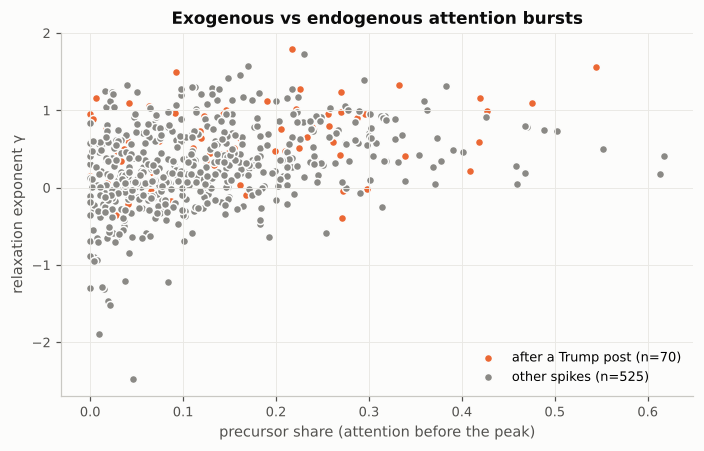

In [37]:
rows = []
for art, (dom, a1, a2) in targets.items():
    if art not in views: continue
    s = views[art].dropna()
    if dom == "policy & geopolitics":
        mask = orig[f"topic_{a1}"] if a2 == "topic" else orig.entities.map(lambda es: any(t in es for t in a1))
    else:
        mask = orig.text_nourl.str.contains(a1, case=a2, regex=True)
    pdays = set(orig.loc[mask, "t_et"].dt.tz_localize(None).dt.normalize())
    for pk in GEO.find_spikes(s, k=4):
        g_, pre_, pk_share = GEO.burst_shape(s, pk, horizon=30)
        if np.isfinite(g_):
            rows.append(dict(article=art, domain=dom, peak=pk, gamma=g_, precursor_share=pre_, peak_share=pk_share,
                             trump_triggered=bool({pk, pk - pd.Timedelta("1D")} & pdays)))
bursts = pd.DataFrame(rows)
display(bursts.groupby("trump_triggered")[["gamma", "precursor_share", "peak_share"]].agg(["count", "median"]).round(3))
a_, b_ = bursts[bursts.trump_triggered], bursts[~bursts.trump_triggered]
mw = {col: stats.mannwhitneyu(a_[col], b_[col]).pvalue for col in ["gamma", "precursor_share", "peak_share"]}
print("Mann-Whitney p:", {k: f"{v:.2g}" for k, v in mw.items()})
fig, ax = plt.subplots(figsize=(6.5, 4.2))
for i, (lab, g) in enumerate([("after a Trump post", a_), ("other spikes", b_)]):
    ax.scatter(g.precursor_share, g.gamma, s=28, color=[C[1], PL.GREY][i], label=f"{lab} (n={len(g)})", edgecolors="#fcfcfb")
ax.set_xlabel("precursor share (attention before the peak)"); ax.set_ylabel("relaxation exponent γ")
ax.legend(); ax.set_title("Exogenous vs endogenous attention bursts"); save(fig, "F6_bursts")
SUMMARY.update(burst_gamma_trump=a_.gamma.median(), burst_gamma_other=b_.gamma.median(), burst_gamma_p=mw["gamma"],
               burst_n_trump=len(a_), burst_n_other=len(b_))

#### Findings F: posts trigger heavy-tailed cascades of collective attention, well beyond politics
* **Foreign publics.** A post about a country raises attention to the *Donald Trump* article **in that country's language**, relative to all other languages. The pooled effect is 0.14 SD, z = 7.2. It is significant in 10 of 18 languages: Hungarian, Polish, Portuguese, Japanese, Danish, Turkish, Vietnamese, Hindi, Hebrew and Ukrainian. It is not significant in the largest editions (Chinese, Spanish, Russian, French, German, Arabic, Persian), where attention to Trump is already high every day.
* **Beyond politics.** **26 of 40 targets** respond after FDR, and **13.0%** of 1,172 post-events exceed z = 2 (2.3% expected).

  | Domain | Mean z | Share of events with z > 2 | Main examples |
  |---|---|---|---|
  | **Entertainment** (strongest) | 2.26 | 39% | Jimmy Kimmel +106% on average and up to **+6,270%** (17 Sep 2025); Kennedy Center +91% over 21 events; Taylor Swift +77%; Springsteen +69% |
  | **Brands** | 0.87 | | Cracker Barrel +463%, Jaguar +63%, TikTok +22% |
  | **Places and heritage** | 0.71 | | Columbus Day +120% |
  | **Policy and geopolitics** | 0.49 | | Greenland +77% with no pre-trend; Panama Canal, Zelensky, NATO |
  | **Sport** | 0.43 | | Washington Commanders +77%, peaking at +430% after his July 2025 demand to restore the old name; LIV Golf +56%; UFC +25% |
  | **Health and science** (weakest) | 0.22 | | only *Paracetamol* responds (+16%), and attention was already rising |
* **Sudden vs surge-riding.** Of the significant spikes, 82 had no build-up before the post and 70 joined a surge already under way. Examples of joining a surge are Cracker Barrel's logo row, Sydney Sweeney's advert, the Kennedy Center and Epstein. A sudden spike on the same day as major news (e.g. Gaza on 7 Oct 2023) cannot be credited to the post. Daily data cannot separate the two, so the cleanest cases of him *creating* attention are those with no pre-trend and no coinciding news: Greenland (Jan 2025), Washington Commanders (Jul 2025) and Columbus Day.
* **Brands' stocks move too.** 6 of 37 brand-mention events fall in the stock's most extreme 2% of 2-day moves (binomial p = 9×10⁻⁵):
  * Intel +15% (Jun 2026) and −10% (Aug 2026);
  * Cracker Barrel +14% (26 Aug 2025);
  * Tesla +13% and +14% (Mar 2025, the "buy a Tesla" posts);
  * American Eagle +11% (4 Aug 2025, Sydney Sweeney).

  Mentions of Apple (22 events) have no effect: very large firms absorb the attention.
* **Heavy-tailed cascades.** 618 positive cascades produced 46 million extra views, and **the top 10% of events produced 84% of them**. The tail is consistent with a power law, α = 1.83 ($p_{gof}=0.59$); a lognormal is statistically indistinguishable. Like viral cascades on social media, almost all of his impact comes from a handful of events.
* **Burst mechanism.** Spikes that follow his posts relax **faster** (median γ = 0.64 vs 0.26 for other spikes, p = 10⁻⁸) and have **more build-up** beforehand (precursor share 0.16 vs 0.10, p = 3×10⁻⁴). In Crane–Sornette terms, his bursts are *exogenous-like in their decay*: the attention he triggers fades quickly rather than spreading endogenously. Yet they often ride on interest that is already building.

## Part G. A mechanism: opinion dynamics driven by his real posts
Observational data show *that* attention responds. They cannot show *how* a single, hyper-active broadcaster shapes opinions in a networked population, so we model it. We use a **bounded-confidence (Deffuant) model** on a scale-free network of $N$ agents with opinions $x\in[-1,1]$. Agents within $\varepsilon$ of each other compromise. A **media agent** broadcasts his *actual* daily stance towards a target. Its daily reach is set by how many posts he made about the target that day, and it reaches a set of followers concentrated on network hubs. We compare three versions:
* **real:** his actual stance and timing;
* **shuffled:** the same days in random order, which keeps the content but destroys the burstiness;
* **no media:** no broadcaster.

A phase diagram over $\varepsilon$ and the follower share then shows when a single broadcaster produces **consensus, polarisation or fragmentation**. The scenario runs use $\varepsilon=0.45$. Near this value, peers on their own usually settle into two opinion clusters, so we can see whether the broadcaster deepens that split or dissolves it. Polarisation is measured by the opinion standard deviation and the bimodality coefficient (BC > 0.555 indicates bimodality).

final_mean        final_sd        bimodality        followers_mean        others_mean       
                                            mean    std     mean    std       mean    std           mean    std        mean    std
target                       scenario                                                                                             
China (geopolitics)          no media      0.006  0.019    0.361  0.117      0.527  0.308            NaN    NaN       0.006  0.019
                             real          0.029  0.013    0.179  0.027      0.208  0.193          0.025  0.014       0.031  0.015
                             shuffled      0.012  0.020    0.165  0.016      0.139  0.134          0.017  0.022       0.011  0.019
Democrats (domestic leaning) no media      0.006  0.019    0.361  0.117      0.527  0.308            NaN    NaN       0.006  0.019
                             real         -0.225  0.008    0.181  0.018      0.457  0.113         -0.285  0.007      -0.199  0.011
                             shuffled     -0.237  0.008    0.183  0.028      0.482  0.106         -0.257  0.003      -0.228  0.011

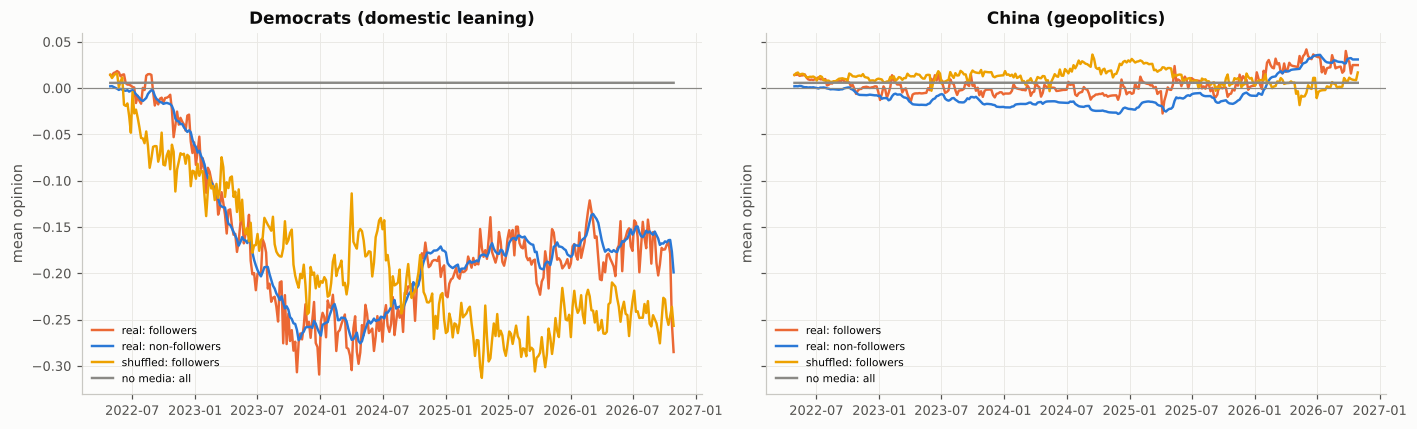

In [38]:
o = own.assign(date=own.t_et.dt.tz_localize(None).dt.normalize())
cal = pd.DataFrame(index=pd.date_range(o.date.min(), o.date.max(), freq="D"))

def daily_target(entities):
    m = o.entities.map(lambda es: any(e in es for e in entities))
    sub = o[m].copy(); sub["s"] = [np.mean([d[e] for e in entities if e in d]) for d in sub.ent_sent]
    g = sub.groupby("date")["s"]
    return g.mean().reindex(cal.index), g.size().reindex(cal.index).fillna(0)

OD_TARGETS = {"Democrats (domestic leaning)": ["Democrats", "Joe Biden", "Kamala Harris"],
              "China (geopolitics)": ["China", "Xi Jinping"]}
OD_SEEDS = 3 if FAST else 8
OD_EPS = 0.45   # confidence bound for the scenario runs (peers alone: typically two clusters)
od_rows, od_hist = [], {}
for tname, ents_ in OD_TARGETS.items():
    s_t, n_t = daily_target(ents_)
    reach = 1 - np.exp(-n_t.values / 2.0)
    perm = np.random.default_rng(0).permutation(len(s_t))
    for scen, (ss, rr, ff) in {"real": (s_t.values, reach, 0.3), "shuffled": (s_t.values[perm], reach[perm], 0.3),
                               "no media": (s_t.values, reach, 0.0)}.items():
        hs = []
        for seed in range(OD_SEEDS):
            h, xfin, fol = GEO.deffuant_media(ss, rr, N=1000, eps=OD_EPS, mu_media=0.1, follower_frac=ff, seed=seed)
            hs.append(h); od_rows.append(dict(target=tname, scenario=scen, seed=seed, final_mean=h["mean"].iloc[-1],
                                              final_sd=h["sd"].iloc[-1], bimodality=h["bimodality"].iloc[-1],
                                              followers_mean=h.mean_followers.iloc[-1], others_mean=h.mean_others.iloc[-1]))
        od_hist[(tname, scen)] = pd.concat(hs).groupby("t").mean()
od = pd.DataFrame(od_rows)
display(od.groupby(["target", "scenario"])[["final_mean", "final_sd", "bimodality", "followers_mean", "others_mean"]].agg(["mean", "std"]).round(3))
fig, axes = plt.subplots(1, len(OD_TARGETS), figsize=(13, 4), sharey=True)
for a, tname in zip(np.atleast_1d(axes), OD_TARGETS):
    for i, scen in enumerate(["real", "shuffled", "no media"]):
        h = od_hist[(tname, scen)]; dates = cal.index[h.index.values]
        a.plot(dates, h["mean_followers"] if scen != "no media" else h["mean"], color=[C[1], C[3], PL.GREY][i], label=f"{scen}: followers" if scen != "no media" else "no media: all")
        if scen == "real": a.plot(dates, h["mean_others"], color=C[0], label="real: non-followers")
    a.axhline(0, color=PL.GREY, lw=0.8); a.set_title(tname); a.set_ylabel("mean opinion"); a.legend(fontsize=7)
save(fig, "G1_opinion_dynamics");

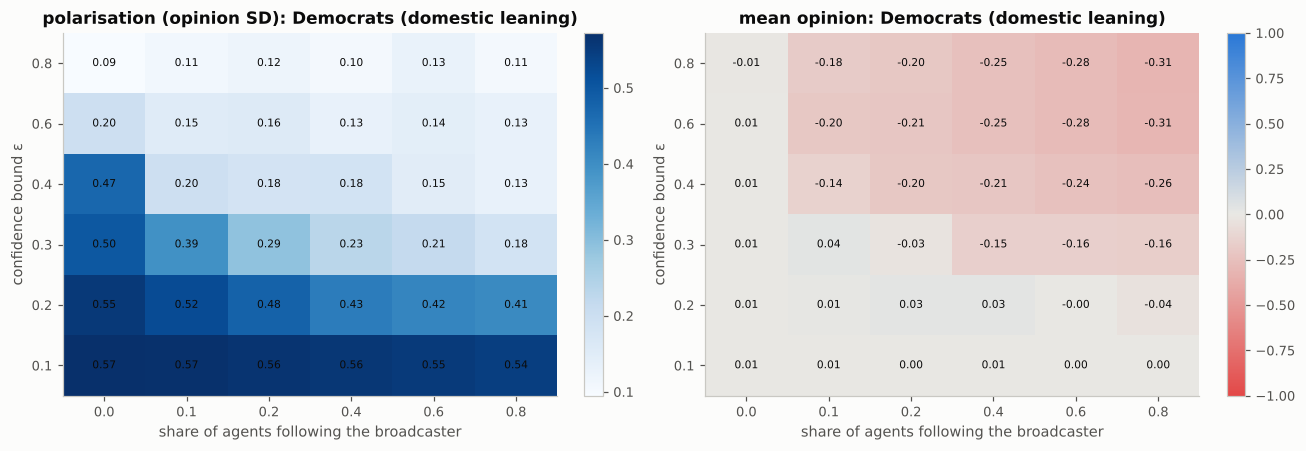

In [39]:
tname = list(OD_TARGETS)[0]; s_t, n_t = daily_target(OD_TARGETS[tname]); reach = 1 - np.exp(-n_t.values / 2.0)
EPS = [0.1, 0.2, 0.3, 0.4, 0.6, 0.8]; FOL = [0.0, 0.1, 0.2, 0.4, 0.6, 0.8]
sd_grid = np.zeros((len(EPS), len(FOL))); mean_grid = np.zeros_like(sd_grid)
for i, e in enumerate(EPS):
    for j, f in enumerate(FOL):
        r_ = [GEO.deffuant_media(s_t.values, reach, N=600, eps=e, mu_media=0.1, follower_frac=f, seed=sd, record_every=10**6)[1] for sd in range(2 if FAST else 4)]
        sd_grid[i, j] = np.mean([x.std() for x in r_]); mean_grid[i, j] = np.mean([x.mean() for x in r_])
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for a, g, title, cmap in [(ax[0], sd_grid, "polarisation (opinion SD)", "Blues"), (ax[1], mean_grid, "mean opinion", DIV_CMAP)]:
    im = a.imshow(g, origin="lower", aspect="auto", cmap=cmap, **({} if cmap == "Blues" else dict(vmin=-1, vmax=1)))
    a.set_xticks(range(len(FOL)), FOL); a.set_yticks(range(len(EPS)), EPS); a.grid(False)
    a.set_xlabel("share of agents following the broadcaster"); a.set_ylabel("confidence bound ε"); a.set_title(f"{title}: {tname}")
    for (ii, jj), v in np.ndenumerate(g): a.text(jj, ii, f"{v:.2f}", ha="center", va="center", fontsize=7, color=PL.INK)
    plt.colorbar(im, ax=a, fraction=0.04)
save(fig, "G2_phase_diagram");
SUMMARY.update(od_real_sd=od[(od.scenario == "real")].final_sd.mean(), od_nomedia_sd=od[(od.scenario == "no media")].final_sd.mean())

#### Findings G: a one-sided broadcaster homogenises opinion, above a threshold
* **Without a broadcaster** (ε = 0.45), peers settle into two opinion clusters (SD 0.36). Adding his **real** Democrats-stance broadcast **halves the dispersion** (SD 0.18). It pulls the whole population negative (mean −0.23): followers reach −0.29 and, through the network, *non-followers* reach −0.20. The China broadcast homogenises in the same way (SD 0.18) but leaves the mean near zero, because his China stance is mixed.
* **Timing does not matter here.** Shuffling the days (same content, no burstiness) gives nearly the same outcome (mean −0.24, SD 0.18). In this model *what* is broadcast matters more than *when*.
* **Phase diagram.** For small confidence bounds (ε ≤ 0.2), the population stays **fragmented** (SD 0.41–0.57) whatever the follower share. For ε ≥ 0.4 with any followers, or ε = 0.3 with ≥ 40% followers, the broadcaster drives **consensus around his own stance** (SD ≤ 0.23, mean −0.14 to −0.31). The transition sits near **ε ≈ 0.3**. A single persistent broadcaster can either unify or fail to reach a population, depending on how open its members are to differing views.
* *Caveat:* this is a mechanism, not a measurement. It shows what the observed posting series *could* do under standard assumptions.

## Synthesis: what kind of complex system is this?
1. **An excitable point process, held below criticality.** His posting is bursty (B ≈ 0.45), long-memory (α_DFA ≈ 0.6–0.8) and self-exciting on two timescales (n ≈ 0.66). The system **never approaches n = 1**: it is excitable but self-limiting, and becomes *more* externally driven in news-heavy periods (n dropped to 0.39 after Liberation Day).
2. **Preferential attention.** The audience rewards intensity (all caps, conflict, tariffs, war). His amplification follows linear preferential attachment (γ ≈ 1). Both mechanisms concentrate attention on a few items.
3. **A hub-and-spoke, rapidly rewiring world.** A disassortative network with 7 robust thematic communities, whose ties turn over by about 70% each quarter. His geopolitics is a **fused multiplex** (P ≈ 0.9), and it went through a **regime shift** when he took office.
4. **Impact = heavy-tailed cascades of collective attention.** The measurable real-world footprint is not a steady push on markets or polls, which tested null at daily scales. It is **intermittent cascades of attention**: within hours in markets (×1.5 volatility after tariff posts), within days in public attention across entertainment, brands, sport, heritage, geopolitics and foreign publics. The top 10% of events carry 84% of the effect, and the resulting bursts decay fast. This is the signature of a system near, but below, the threshold for sustained cascades.

**Limitations.**
* Daily and hourly data cannot separate a post's effect from the same-day news it reacts to (pre-trends are shown, but coincident news remains a confounder).
* Lexicon-based entity, topic and sentiment tagging is noisy. Validate a random sample of about 100 posts by hand and report the precision.
* Engagement counts are snapshots, and deleted posts are missing.
* Wikipedia views measure English-language and Wikipedia-using publics.
* Hourly market data cover only about the last 2–3 years.
* Many tests are run; results are reported after Benjamini–Hochberg FDR control.

In [40]:
summary = pd.Series(SUMMARY, dtype=object).to_frame("value")
with pd.option_context("display.max_rows", 300):
    display(summary)
summary.to_csv(f"{FIG_DIR}/summary_metrics.csv")

,value
share_posts_midnight_6am,0.0759
B_raw,0.4452
B_rescaled,0.408
M_log,0.4097
tau_alpha,4.3555
tau_xmin_min,657.8069
DFA_alpha_hourly,0.6183
DFA_alpha_daily,0.7672
hawkes_n_constant,0.5873
hawkes_n_circadian,0.5753
